In [1]:
print("Cyberattack Detection Project")
print("Python environment is working successfully!")

Cyberattack Detection Project
Python environment is working successfully!


In [2]:
import pandas as pd

print("Pandas imported successfully!")

Pandas imported successfully!


In [3]:
# Load the training dataset
df_train = pd.read_csv("../dataset/UNSW_NB15_training-set.csv")

print("Training dataset loaded successfully!")

Training dataset loaded successfully!


In [4]:
print("Training Dataset Shape:", df_train.shape)

Training Dataset Shape: (175341, 45)


In [5]:
df_train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [6]:
for column in df_train.columns:
    print(column)

id
dur
proto
service
state
spkts
dpkts
sbytes
dbytes
rate
sttl
dttl
sload
dload
sloss
dloss
sinpkt
dinpkt
sjit
djit
swin
stcpb
dtcpb
dwin
tcprtt
synack
ackdat
smean
dmean
trans_depth
response_body_len
ct_srv_src
ct_state_ttl
ct_dst_ltm
ct_src_dport_ltm
ct_dst_sport_ltm
ct_dst_src_ltm
is_ftp_login
ct_ftp_cmd
ct_flw_http_mthd
ct_src_ltm
ct_srv_dst
is_sm_ips_ports
attack_cat
label


In [7]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

In [8]:
print("Total missing values:", df_train.isnull().sum().sum())

Total missing values: 0


In [9]:
df_train["label"].value_counts()

label
1    119341
0     56000
Name: count, dtype: int64

In [10]:
label_percentage = df_train["label"].value_counts(normalize=True) * 100

print(label_percentage)

label
1    68.062233
0    31.937767
Name: proportion, dtype: float64


In [11]:
df_train["attack_cat"].value_counts()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

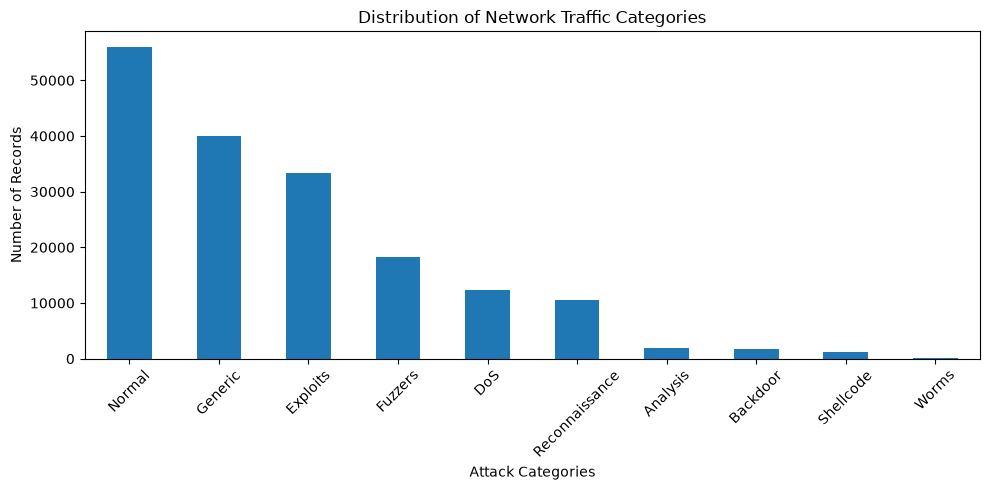

In [12]:
import matplotlib.pyplot as plt

df_train["attack_cat"].value_counts().plot(
    kind="bar",
    figsize=(10, 5),
    title="Distribution of Network Traffic Categories"
)

plt.xlabel("Attack Categories")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
df_train[
    ['dur', 'proto', 'service', 'state',
     'spkts', 'dpkts', 'sbytes', 'dbytes',
     'rate', 'sttl', 'dttl', 'label', 'attack_cat']
].head(10)

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,label,attack_cat
0,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,0,Normal
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,0,Normal
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,0,Normal
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,0,Normal
4,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,0,Normal
5,0.380537,tcp,-,FIN,10,6,534,268,39.417980,254,252,0,Normal
6,0.637109,tcp,-,FIN,10,8,534,354,26.683033,254,252,0,Normal
7,0.521584,tcp,-,FIN,10,8,534,354,32.593026,254,252,0,Normal
8,0.542905,tcp,-,FIN,10,8,534,354,31.313031,254,252,0,Normal
9,0.258687,tcp,-,FIN,10,6,534,268,57.985135,254,252,0,Normal


In [14]:
df_train.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,...,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,87671.000000,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,...,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,50616.731112,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,...,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,1.000000,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,43836.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,87671.000000,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,131506.000000,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,...,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,175341.000000,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


In [15]:
print("Columns containing time-related information:")

for column in df_train.columns:
    if "time" in column.lower() or "date" in column.lower():
        print(column)

Columns containing time-related information:


In [16]:
df_original = pd.read_csv("../dataset/UNSW-NB15_4.csv")

print("Original dataset loaded successfully!")

Original dataset loaded successfully!


In [17]:
df_original = pd.read_csv("../dataset/UNSW-NB15_1.csv")

print("Original dataset loaded successfully!")

Original dataset loaded successfully!


C:\Users\moham\AppData\Local\Temp\ipykernel_18628\1089313562.py:1: DtypeWarning: Columns (1: 1390, 3: 53, 47: Unnamed: 47) have mixed types. Specify dtype option on import or set low_memory=False.
  df_original = pd.read_csv("../dataset/UNSW-NB15_1.csv")


In [18]:
print("Dataset Shape:", df_original.shape)

print("\nColumn Names:")
for column in df_original.columns:
    print(column)

Dataset Shape: (700000, 49)

Column Names:
59.166.0.0
1390
149.171.126.6
53
udp
CON
0.001055
132
164
31
29
0
0.1
dns
500473.9375
621800.9375
2
2.1
0.2
0.3
0.4
0.5
66
82
0.6
0.7
0.8
0.9
1421927414
1421927414.1
0.017
0.013
0.10
0.11
0.12
0.13
0.14
0.15
0.16
0.17
3
7
1
3.1
1.1
1.2
1.3
Unnamed: 47
0.18


In [19]:
df_original = pd.read_csv(
    "../dataset/UNSW-NB15_1.csv",
    header=None
)

print("Dataset Shape:", df_original.shape)

df_original.head()

Dataset Shape: (700001, 49)


C:\Users\moham\AppData\Local\Temp\ipykernel_18628\1221000298.py:1: DtypeWarning: Columns (1: 1, 3: 3, 47: 47) have mixed types. Specify dtype option on import or set low_memory=False.
  df_original = pd.read_csv(


,0,1,2,3,4,5,6,7,8,9,...,39,40,41,42,43,44,45,46,47,48
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0


In [20]:
column_names = [
    'srcip', 'sport', 'dstip', 'dsport', 'proto', 'state',
    'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss',
    'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts',
    'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz',
    'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime',
    'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack',
    'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd',
    'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst',
    'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm',
    'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label'
]

df_original.columns = column_names

print("Column names assigned successfully!")

print("\nTimestamp columns:")
print(df_original[['Stime', 'Ltime']].head())

Column names assigned successfully!

Timestamp columns:
        Stime       Ltime
0  1421927414  1421927414
1  1421927414  1421927414
2  1421927414  1421927414
3  1421927414  1421927414
4  1421927414  1421927414


In [21]:
print("Columns containing time-related information:")

for column in df_train.columns:
    if "time" in column.lower() or "date" in column.lower():
        print(column)

Columns containing time-related information:


In [22]:
print("Earliest Start Time:", df_original['Stime'].min())

print("Latest Start Time:", df_original['Stime'].max())

print("Unique Start Times:", df_original['Stime'].nunique())

print("\nTimestamp Data Types:")
print(df_original[['Stime', 'Ltime']].dtypes)

Earliest Start Time: 1421927377
Latest Start Time: 1421955842
Unique Start Times: 27568

Timestamp Data Types:
Stime    int64
Ltime    int64
dtype: object


In [23]:
df_original['Stime_readable'] = pd.to_datetime(
    df_original['Stime'],
    unit='s',
    utc=True
)

print("First 5 converted timestamps:")
print(df_original[['Stime', 'Stime_readable']].head())

print("\nEarliest Date:", df_original['Stime_readable'].min())
print("Latest Date:", df_original['Stime_readable'].max())

First 5 converted timestamps:
        Stime            Stime_readable
0  1421927414 2015-01-22 11:50:14+00:00
1  1421927414 2015-01-22 11:50:14+00:00
2  1421927414 2015-01-22 11:50:14+00:00
3  1421927414 2015-01-22 11:50:14+00:00
4  1421927414 2015-01-22 11:50:14+00:00

Earliest Date: 2015-01-22 11:49:37+00:00
Latest Date: 2015-01-22 19:44:02+00:00


In [24]:
is_sorted = df_original['Stime'].is_monotonic_increasing

print("Are records arranged chronologically?", is_sorted)

Are records arranged chronologically? False


In [25]:
df_original = df_original.sort_values(
    by='Stime'
).reset_index(drop=True)

print(
    "Chronologically sorted:",
    df_original['Stime'].is_monotonic_increasing
)

Chronologically sorted: True


In [26]:
timestamp_counts = df_original['Stime'].value_counts()

print("Number of unique timestamps:", len(timestamp_counts))

print("\nRecords at each timestamp:")
print(timestamp_counts.describe())

Number of unique timestamps: 27568

Records at each timestamp:
count    27568.000000
mean        25.391795
std         13.427447
min          1.000000
25%         20.000000
50%         23.000000
75%         26.000000
max        426.000000
Name: count, dtype: float64


In [27]:
unique_times = sorted(df_original['Stime'].unique())

time_gaps = pd.Series(unique_times).diff()

print("Time Interval Distribution (seconds):")
print(time_gaps.describe())

Time Interval Distribution (seconds):
count    27567.000000
mean         1.032575
std          5.171284
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        859.000000
dtype: float64


In [28]:
attack_per_second = df_original.groupby('Stime')['label'].agg(
    total_records='count',
    attack_records='sum'
)

attack_per_second['normal_records'] = (
    attack_per_second['total_records']
    - attack_per_second['attack_records']
)

print(attack_per_second.head(10))

            total_records  attack_records  normal_records
Stime                                                    
1421927377              4               0               4
1421927381              2               0               2
1421927414             18               1              17
1421927415             24               1              23
1421927416             21               1              20
1421927417             18               1              17
1421927418             20               1              19
1421927419             21               2              19
1421927420             21               1              20
1421927421             20               2              18


In [29]:
attack_per_second['attack_percentage'] = (
    attack_per_second['attack_records']
    / attack_per_second['total_records']
) * 100

print(attack_per_second.head(10))

            total_records  attack_records  normal_records  attack_percentage
Stime                                                                       
1421927377              4               0               4           0.000000
1421927381              2               0               2           0.000000
1421927414             18               1              17           5.555556
1421927415             24               1              23           4.166667
1421927416             21               1              20           4.761905
1421927417             18               1              17           5.555556
1421927418             20               1              19           5.000000
1421927419             21               2              19           9.523810
1421927420             21               1              20           4.761905
1421927421             20               2              18          10.000000


In [30]:
traffic_features = df_original.groupby('Stime').agg(
    total_connections=('Stime', 'count'),
    avg_source_packets=('Spkts', 'mean'),
    avg_destination_packets=('Dpkts', 'mean'),
    avg_source_bytes=('sbytes', 'mean'),
    avg_destination_bytes=('dbytes', 'mean'),
    avg_duration=('dur', 'mean')
)

print("Network Behaviour Features:")
print(traffic_features.head(10))

Network Behaviour Features:
            total_connections  avg_source_packets  avg_destination_packets  \
Stime                                                                        
1421927377                  4            6.000000                 0.000000   
1421927381                  2            5.000000                 0.000000   
1421927414                 18            8.777778                 8.444444   
1421927415                 24           11.750000                11.833333   
1421927416                 21           14.857143                15.619048   
1421927417                 18           13.888889                14.111111   
1421927418                 20           19.100000                19.800000   
1421927419                 21           22.285714                22.666667   
1421927420                 21           23.809524                24.380952   
1421927421                 20           13.700000                14.700000   

            avg_source_bytes  avg_d

In [31]:
attack_labels = df_original.groupby('Stime')['label'].max()

attack_labels = attack_labels.rename('attack')

print("Attack Labels:")
print(attack_labels.head(10))

Attack Labels:
Stime
1421927377    0
1421927381    0
1421927414    1
1421927415    1
1421927416    1
1421927417    1
1421927418    1
1421927419    1
1421927420    1
1421927421    1
Name: attack, dtype: int64


In [32]:
dbn_data = traffic_features.join(attack_labels)

print("Combined Dataset:")
print(dbn_data.head(10))

Combined Dataset:
            total_connections  avg_source_packets  avg_destination_packets  \
Stime                                                                        
1421927377                  4            6.000000                 0.000000   
1421927381                  2            5.000000                 0.000000   
1421927414                 18            8.777778                 8.444444   
1421927415                 24           11.750000                11.833333   
1421927416                 21           14.857143                15.619048   
1421927417                 18           13.888889                14.111111   
1421927418                 20           19.100000                19.800000   
1421927419                 21           22.285714                22.666667   
1421927420                 21           23.809524                24.380952   
1421927421                 20           13.700000                14.700000   

            avg_source_bytes  avg_destination

In [33]:
# Check the size of the dataset
print("Dataset Shape:", dbn_data.shape)

# Check for missing values
print("\nMissing Values:")
print(dbn_data.isnull().sum())

# Count normal and attack observations
print("\nAttack Distribution:")
print(dbn_data['attack'].value_counts())

# Check the timestamp order
print("\nTimestamp Sorted:", dbn_data.index.is_monotonic_increasing)

Dataset Shape: (27568, 7)

Missing Values:
total_connections          0
avg_source_packets         0
avg_destination_packets    0
avg_source_bytes           0
avg_destination_bytes      0
avg_duration               0
attack                     0
dtype: int64

Attack Distribution:
attack
0    21078
1     6490
Name: count, dtype: int64

Timestamp Sorted: True


In [34]:
# Calculate the time difference between consecutive observations
time_difference = dbn_data.index.to_series().diff()

# Display time gap statistics
print("Time Gap Statistics:")
print(time_difference.describe())

# Count different time gaps
print("\nMost Common Time Gaps:")
print(time_difference.value_counts().head(10))

Time Gap Statistics:
count    27567.000000
mean         1.032575
std          5.171284
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        859.000000
Name: Stime, dtype: float64

Most Common Time Gaps:
Stime
1.0      27560
2.0          3
4.0          1
33.0         1
3.0          1
859.0        1
Name: count, dtype: int64


In [35]:
# Calculate time differences
time_difference = dbn_data.index.to_series().diff()

# Find timestamps where the gap is greater than 1 second
gap_locations = time_difference[time_difference > 1]

print("Locations of Time Gaps:")
print(gap_locations)

print("\nTotal Number of Time Gaps:", len(gap_locations))

Locations of Time Gaps:
Stime
1421927381      4.0
1421927414     33.0
1421934205      2.0
1421945087      2.0
1421947350      2.0
1421949168      3.0
1421955321    859.0
Name: Stime, dtype: float64

Total Number of Time Gaps: 7


In [36]:
# Calculate time differences
time_difference = dbn_data.index.to_series().diff()

# Create a new sequence whenever the time gap exceeds 1 second
dbn_data['sequence_id'] = (
    time_difference.fillna(1) > 1
).cumsum()

# Count observations in each sequence
sequence_sizes = dbn_data.groupby('sequence_id').size()

print("Number of Sequences:", dbn_data['sequence_id'].nunique())

print("\nObservations in Each Sequence:")
print(sequence_sizes)

Number of Sequences: 8

Observations in Each Sequence:
sequence_id
0        1
1        1
2     6790
3    10881
4     2262
5     1816
6     5295
7      522
dtype: int64


In [37]:
# Display statistical information about network features
print(dbn_data.drop(
    columns=['attack', 'sequence_id']
).describe())

       total_connections  avg_source_packets  avg_destination_packets  \
count       27568.000000        27568.000000             27568.000000   
mean           25.391795           38.963582                49.722486   
std            13.427447           23.360797                43.546354   
min             1.000000            5.000000                 0.000000   
25%            20.000000           26.408824                27.000000   
50%            23.000000           33.000000                34.583333   
75%            26.000000           42.956522                56.800000   
max           426.000000          544.100000               638.017699   

       avg_source_bytes  avg_destination_bytes  avg_duration  
count      27568.000000           27568.000000  27568.000000  
mean        4828.551681           40952.564659      0.684110  
std         9267.218802           58045.049841      3.037708  
min          384.000000               0.000000      0.000000  
25%         3039.226489    

In [38]:
# Select network behaviour features
feature_columns = [
    'total_connections',
    'avg_source_packets',
    'avg_destination_packets',
    'avg_source_bytes',
    'avg_destination_bytes',
    'avg_duration'
]

# Calculate percentile thresholds
thresholds = dbn_data[feature_columns].quantile([0.25, 0.75])

print("Discretization Thresholds:")
print(thresholds)

Discretization Thresholds:
      total_connections  avg_source_packets  avg_destination_packets  \
0.25               20.0           26.408824                     27.0   
0.75               26.0           42.956522                     56.8   

      avg_source_bytes  avg_destination_bytes  avg_duration  
0.25       3039.226489           11312.309524      0.190726  
0.75       5463.774927           55619.896522      0.527247  


In [39]:
# Calculate the 80% split position
split_position = int(len(dbn_data) * 0.80)

# First 80%: Training data
train_data = dbn_data.iloc[:split_position].copy()

# Last 20%: Testing data
test_data = dbn_data.iloc[split_position:].copy()

print("Training Dataset:", train_data.shape)
print("Testing Dataset:", test_data.shape)

print("\nTraining Time Range:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting Time Range:")
print(test_data.index.min(), "to", test_data.index.max())

Training Dataset: (22054, 8)
Testing Dataset: (5514, 8)

Training Time Range:
1421927377 to 1421949470

Testing Time Range:
1421949471 to 1421955842


In [40]:
# Select network behaviour features
feature_columns = [
    'total_connections',
    'avg_source_packets',
    'avg_destination_packets',
    'avg_source_bytes',
    'avg_destination_bytes',
    'avg_duration'
]

# Calculate thresholds using training data only
train_thresholds = train_data[feature_columns].quantile([0.25, 0.75])

print("Training Data Discretization Thresholds:")
print(train_thresholds)

Training Data Discretization Thresholds:
      total_connections  avg_source_packets  avg_destination_packets  \
0.25               20.0           26.090909                26.580616   
0.75               26.0           42.663043                56.306856   

      avg_source_bytes  avg_destination_bytes  avg_duration  
0.25       3016.146927           11121.903333      0.191689  
0.75       5460.339583           55268.533764      0.534715  


In [41]:
import numpy as np

# Create a copy of training data
train_discrete = train_data.copy()

# Convert numerical features into Low, Medium and High
for feature in feature_columns:

    q1 = train_thresholds.loc[0.25, feature]
    q3 = train_thresholds.loc[0.75, feature]

    train_discrete[feature] = np.select(
        [
            train_discrete[feature] <= q1,
            train_discrete[feature] <= q3
        ],
        [0, 1],
        default=2
    )

print(train_discrete[feature_columns].head())

            total_connections  avg_source_packets  avg_destination_packets  \
Stime                                                                        
1421927377                  0                   0                        0   
1421927381                  0                   0                        0   
1421927414                  0                   0                        0   
1421927415                  1                   0                        0   
1421927416                  1                   0                        0   

            avg_source_bytes  avg_destination_bytes  avg_duration  
Stime                                                              
1421927377                 0                      0             2  
1421927381                 0                      0             0  
1421927414                 0                      0             2  
1421927415                 0                      0             2  
1421927416                 1                 

In [42]:
# Create a copy of testing data
test_discrete = test_data.copy()

# Apply training thresholds to testing data
for feature in feature_columns:

    q1 = train_thresholds.loc[0.25, feature]
    q3 = train_thresholds.loc[0.75, feature]

    test_discrete[feature] = np.select(
        [
            test_discrete[feature] <= q1,
            test_discrete[feature] <= q3
        ],
        [0, 1],
        default=2
    )

print(test_discrete[feature_columns].head())

            total_connections  avg_source_packets  avg_destination_packets  \
Stime                                                                        
1421949471                  1                   1                        1   
1421949472                  1                   0                        0   
1421949473                  1                   1                        1   
1421949474                  0                   1                        1   
1421949475                  0                   1                        1   

            avg_source_bytes  avg_destination_bytes  avg_duration  
Stime                                                              
1421949471                 0                      1             0  
1421949472                 0                      0             0  
1421949473                 0                      1             0  
1421949474                 0                      1             1  
1421949475                 2                 

In [43]:
# Check training dataset
print("Training Dataset Shape:", train_discrete.shape)

# Check testing dataset
print("Testing Dataset Shape:", test_discrete.shape)

# Check missing values in training data
print("\nMissing Values in Training:")
print(train_discrete.isnull().sum())

# Check missing values in testing data
print("\nMissing Values in Testing:")
print(test_discrete.isnull().sum())

# Check attack distribution
print("\nTraining Attack Distribution:")
print(train_discrete['attack'].value_counts())

print("\nTesting Attack Distribution:")
print(test_discrete['attack'].value_counts())

Training Dataset Shape: (22054, 8)
Testing Dataset Shape: (5514, 8)

Missing Values in Training:
total_connections          0
avg_source_packets         0
avg_destination_packets    0
avg_source_bytes           0
avg_destination_bytes      0
avg_duration               0
attack                     0
sequence_id                0
dtype: int64

Missing Values in Testing:
total_connections          0
avg_source_packets         0
avg_destination_packets    0
avg_source_bytes           0
avg_destination_bytes      0
avg_duration               0
attack                     0
sequence_id                0
dtype: int64

Training Attack Distribution:
attack
0    15564
1     6490
Name: count, dtype: int64

Testing Attack Distribution:
attack
0    5514
Name: count, dtype: int64


In [44]:
# Check attack distribution in each training sequence
print("TRAINING SEQUENCES")
print(
    train_data.groupby('sequence_id')['attack']
    .agg(['count', 'sum'])
)

# Check attack distribution in each testing sequence
print("\nTESTING SEQUENCES")
print(
    test_data.groupby('sequence_id')['attack']
    .agg(['count', 'sum'])
)

TRAINING SEQUENCES
             count   sum
sequence_id             
0                1     0
1                1     0
2             6790  6310
3            10881   180
4             2262     0
5             1816     0
6              303     0

TESTING SEQUENCES
             count  sum
sequence_id            
6             4992    0
7              522    0


In [45]:
block_results = []

for seq_id, group in dbn_data.groupby('sequence_id'):

    group = group.sort_index()

    # Divide the sequence into 10 parts
    block_indices = np.array_split(np.arange(len(group)), 10)

    for block_number, indices in enumerate(block_indices, start=1):

        # Keep each block as a Pandas DataFrame
        block = group.iloc[indices]

        block_results.append({
            'sequence_id': seq_id,
            'block': block_number,
            'observations': len(block),
            'attacks': int(block['attack'].sum()),
            'normal': int((block['attack'] == 0).sum())
        })

block_summary = pd.DataFrame(block_results)

print(block_summary.to_string(index=False))

 sequence_id  block  observations  attacks  normal
           0      1             1        0       1
           0      2             0        0       0
           0      3             0        0       0
           0      4             0        0       0
           0      5             0        0       0
           0      6             0        0       0
           0      7             0        0       0
           0      8             0        0       0
           0      9             0        0       0
           0     10             0        0       0
           1      1             1        0       1
           1      2             0        0       0
           1      3             0        0       0
           1      4             0        0       0
           1      5             0        0       0
           1      6             0        0       0
           1      7             0        0       0
           1      8             0        0       0
           1      9            

In [46]:
# Load the fourth original dataset file
df_original_4 = pd.read_csv(
    "../dataset/UNSW-NB15_4.csv",
    header=None
)

# Assign the column names
df_original_4.columns = column_names

# Display dataset information
print("Dataset Shape:", df_original_4.shape)

print("\nTimestamp Range:")
print("Start:", df_original_4['Stime'].min())
print("End:", df_original_4['Stime'].max())

print("\nAttack Distribution:")
print(df_original_4['label'].value_counts())

print("\nAttack Category Distribution:")
print(df_original_4['attack_cat'].value_counts())

Dataset Shape: (440044, 49)

Timestamp Range:
Start: 1424249984
End: 1424262068

Attack Distribution:
label
0    351150
1     88894
Name: count, dtype: int64

Attack Category Distribution:
attack_cat
Generic             61878
Exploits            11439
 Fuzzers             5390
DoS                  4907
 Reconnaissance      3530
Analysis              670
Backdoor              666
 Shellcode            371
Worms                  43
Name: count, dtype: int64


In [47]:
# Sort File 4 chronologically
df_original_4 = df_original_4.sort_values(
    by='Stime'
).reset_index(drop=True)

# Get unique timestamps
unique_times_4 = np.sort(df_original_4['Stime'].unique())

# Calculate gaps between timestamps
time_gaps_4 = pd.Series(unique_times_4).diff().dropna()

# Display timestamp information
print("Total Records:", len(df_original_4))

print("Unique Timestamps:", len(unique_times_4))

print("\nTimestamp Order:")
print(df_original_4['Stime'].is_monotonic_increasing)

print("\nTime Gap Statistics:")
print(time_gaps_4.describe())

print("\nNumber of Gaps Greater Than 1 Second:")
print((time_gaps_4 > 1).sum())

Total Records: 440044
Unique Timestamps: 11773

Timestamp Order:
True

Time Gap Statistics:
count    11772.000000
mean         1.026504
std          2.720049
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        296.000000
dtype: float64

Number of Gaps Greater Than 1 Second:
8


In [48]:
# Calculate time gaps
time_gaps_4 = pd.Series(unique_times_4).diff()

# Find gaps greater than one second
large_gaps_4 = time_gaps_4[time_gaps_4 > 1]

print("Gaps Greater Than 1 Second:")
print(large_gaps_4)

print("\nTotal Large Gaps:", len(large_gaps_4))

Gaps Greater Than 1 Second:
1         8.0
2         2.0
4         5.0
5         2.0
7         2.0
9         2.0
3748      3.0
5264    296.0
dtype: float64

Total Large Gaps: 8


In [49]:
# Aggregate network traffic features by timestamp

traffic_features_4 = df_original_4.groupby('Stime').agg(
    total_connections=('Stime', 'count'),
    avg_source_packets=('Spkts', 'mean'),
    avg_destination_packets=('Dpkts', 'mean'),
    avg_source_bytes=('sbytes', 'mean'),
    avg_destination_bytes=('dbytes', 'mean'),
    avg_duration=('dur', 'mean')
)

# Create attack labels for each timestamp

attack_labels_4 = df_original_4.groupby('Stime')['label'].max()

attack_labels_4 = attack_labels_4.rename('attack')

# Combine features and target

dbn_data_4 = traffic_features_4.join(attack_labels_4)

# Display results

print("Dataset Shape:", dbn_data_4.shape)

print("\nFirst 10 Observations:")
display(dbn_data_4.head(10))

print("\nAttack Distribution:")
print(dbn_data_4['attack'].value_counts())

Dataset Shape: (11773, 7)

First 10 Observations:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
Stime,,,,,,,
1424249984,1,2.000000,2.000000,56.000000,9.200000e+01,48.948605,0
1424249992,1,4.000000,4.000000,184.000000,1.120000e+02,30.982189,0
1424249994,11,7.636364,3.272727,351.272727,2.029091e+02,35.081613,0
1424249995,1,8.000000,4.000000,344.000000,2.480000e+02,31.233803,0
1424250000,3,581.333333,1114.666667,32444.666667,1.429207e+06,9.631485,0
1424250002,1,368.000000,746.000000,19618.000000,1.087890e+06,20.408854,0
1424250003,1,364.000000,746.000000,19410.000000,1.087890e+06,5.864748,0
1424250005,3,352.666667,616.000000,21620.000000,7.418207e+05,10.148796,0
1424250006,1,354.000000,746.000000,18890.000000,1.087890e+06,13.724829,0



Attack Distribution:
attack
1    10487
0     1286
Name: count, dtype: int64


In [50]:
# Compare training and testing datasets

print("TRAINING DATASET (File 1)")
print("Shape:", dbn_data.shape)

print("\nAttack Distribution:")
print(dbn_data['attack'].value_counts())

print("\nTESTING DATASET (File 4)")
print("Shape:", dbn_data_4.shape)

print("\nAttack Distribution:")
print(dbn_data_4['attack'].value_counts())

# Compare feature columns
print("\nTraining Features:")
print(dbn_data.columns.tolist())

print("\nTesting Features:")
print(dbn_data_4.columns.tolist())

TRAINING DATASET (File 1)
Shape: (27568, 8)

Attack Distribution:
attack
0    21078
1     6490
Name: count, dtype: int64

TESTING DATASET (File 4)
Shape: (11773, 7)

Attack Distribution:
attack
1    10487
0     1286
Name: count, dtype: int64

Training Features:
['total_connections', 'avg_source_packets', 'avg_destination_packets', 'avg_source_bytes', 'avg_destination_bytes', 'avg_duration', 'attack', 'sequence_id']

Testing Features:
['total_connections', 'avg_source_packets', 'avg_destination_packets', 'avg_source_bytes', 'avg_destination_bytes', 'avg_duration', 'attack']


In [51]:
# Calculate time differences between consecutive observations

time_difference_4 = dbn_data_4.index.to_series().diff()

# Create sequence IDs
# A new sequence starts whenever the time gap is greater than 1 second

dbn_data_4['sequence_id'] = (
    time_difference_4.fillna(1) > 1
).cumsum()

# Calculate the size of each sequence

sequence_sizes_4 = dbn_data_4.groupby('sequence_id').size()

print("Total Number of Sequences:", len(sequence_sizes_4))

print("\nSequence Sizes:")
print(sequence_sizes_4)

print("\nTotal Observations:", sequence_sizes_4.sum())

Total Number of Sequences: 9

Sequence Sizes:
sequence_id
0       1
1       1
2       2
3       1
4       2
5       2
6    3739
7    1516
8    6509
dtype: int64

Total Observations: 11773


In [52]:
# Select the six network traffic features

feature_columns = [
    'total_connections',
    'avg_source_packets',
    'avg_destination_packets',
    'avg_source_bytes',
    'avg_destination_bytes',
    'avg_duration'
]

# Prepare training dataset
train_data = dbn_data.copy()

# Prepare testing dataset
test_data = dbn_data_4.copy()

# Check dataset shapes

print("Training Shape:", train_data.shape)
print("Testing Shape:", test_data.shape)

# Check missing values

print("\nTraining Missing Values:")
print(train_data[feature_columns + ['attack']].isnull().sum())

print("\nTesting Missing Values:")
print(test_data[feature_columns + ['attack']].isnull().sum())

Training Shape: (27568, 8)
Testing Shape: (11773, 8)

Training Missing Values:
total_connections          0
avg_source_packets         0
avg_destination_packets    0
avg_source_bytes           0
avg_destination_bytes      0
avg_duration               0
attack                     0
dtype: int64

Testing Missing Values:
total_connections          0
avg_source_packets         0
avg_destination_packets    0
avg_source_bytes           0
avg_destination_bytes      0
avg_duration               0
attack                     0
dtype: int64


In [53]:
# Calculate 25th and 75th percentile thresholds
# using training data only

train_thresholds = train_data[feature_columns].quantile([0.25, 0.75])

print("Training Data Thresholds:")
display(train_thresholds)

Training Data Thresholds:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration
0.25,20.0,26.408824,27.0,3039.226489,11312.309524,0.190726
0.75,26.0,42.956522,56.8,5463.774927,55619.896522,0.527247


In [54]:
# Create a copy of the training dataset

train_discrete = train_data.copy()

# Convert numerical features into three states

for feature in feature_columns:

    q1 = train_thresholds.loc[0.25, feature]

    q3 = train_thresholds.loc[0.75, feature]

    train_discrete[feature] = np.select(
        [
            train_discrete[feature] <= q1,
            train_discrete[feature] <= q3
        ],
        [0, 1],
        default=2
    )

# Display the result

print("Original Training Data:")
display(train_data[feature_columns].head())

print("\nDiscretized Training Data:")
display(train_discrete[feature_columns].head())

Original Training Data:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration
Stime,,,,,,
1421927377,4,6.000000,0.000000,384.000000,0.000000,50.004339
1421927381,2,5.000000,0.000000,1780.000000,0.000000,0.000000
1421927414,18,8.777778,8.444444,2793.555556,1171.111111,17.682186
1421927415,24,11.750000,11.833333,2572.916667,3869.000000,13.536618
1421927416,21,14.857143,15.619048,4543.619048,2955.428571,16.191509



Discretized Training Data:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration
Stime,,,,,,
1421927377,0,0,0,0,0,2
1421927381,0,0,0,0,0,0
1421927414,0,0,0,0,0,2
1421927415,1,0,0,0,0,2
1421927416,1,0,0,1,0,2


In [55]:
# Create a copy of the testing dataset

test_discrete = test_data.copy()

# Apply the training thresholds to testing data

for feature in feature_columns:

    q1 = train_thresholds.loc[0.25, feature]

    q3 = train_thresholds.loc[0.75, feature]

    test_discrete[feature] = np.select(
        [
            test_discrete[feature] <= q1,
            test_discrete[feature] <= q3
        ],
        [0, 1],
        default=2
    )

# Display the original and discretized values

print("Original Testing Data:")
display(test_data[feature_columns].head())

print("\nDiscretized Testing Data:")
display(test_discrete[feature_columns].head())

Original Testing Data:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration
Stime,,,,,,
1424249984,1,2.000000,2.000000,56.000000,9.200000e+01,48.948605
1424249992,1,4.000000,4.000000,184.000000,1.120000e+02,30.982189
1424249994,11,7.636364,3.272727,351.272727,2.029091e+02,35.081613
1424249995,1,8.000000,4.000000,344.000000,2.480000e+02,31.233803
1424250000,3,581.333333,1114.666667,32444.666667,1.429207e+06,9.631485



Discretized Testing Data:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration
Stime,,,,,,
1424249984,0,0,0,0,0,2
1424249992,0,0,0,0,0,2
1424249994,0,0,0,0,0,2
1424249995,0,0,0,0,0,2
1424250000,0,2,2,2,2,2


In [56]:
# Check unique states in training data

print("TRAINING DATA")

for feature in feature_columns:
    print(feature, ":", sorted(train_discrete[feature].unique()))


# Check unique states in testing data

print("\nTESTING DATA")

for feature in feature_columns:
    print(feature, ":", sorted(test_discrete[feature].unique()))

TRAINING DATA
total_connections : [np.int64(0), np.int64(1), np.int64(2)]
avg_source_packets : [np.int64(0), np.int64(1), np.int64(2)]
avg_destination_packets : [np.int64(0), np.int64(1), np.int64(2)]
avg_source_bytes : [np.int64(0), np.int64(1), np.int64(2)]
avg_destination_bytes : [np.int64(0), np.int64(1), np.int64(2)]
avg_duration : [np.int64(0), np.int64(1), np.int64(2)]

TESTING DATA
total_connections : [np.int64(0), np.int64(1), np.int64(2)]
avg_source_packets : [np.int64(0), np.int64(1), np.int64(2)]
avg_destination_packets : [np.int64(0), np.int64(1), np.int64(2)]
avg_source_bytes : [np.int64(0), np.int64(1), np.int64(2)]
avg_destination_bytes : [np.int64(0), np.int64(1), np.int64(2)]
avg_duration : [np.int64(0), np.int64(1), np.int64(2)]


In [57]:
# Select features and target

dbn_columns = feature_columns + ['attack']

# Current observations (time t)

train_t = train_discrete[dbn_columns].copy()

# Next observations (time t+1)
# Shift within each sequence to avoid crossing sequence boundaries

train_t1 = train_discrete.groupby('sequence_id')[dbn_columns].shift(-1)

# Combine current and next observations

train_transitions = pd.concat(
    [
        train_t.add_suffix('_t'),
        train_t1.add_suffix('_t1')
    ],
    axis=1
)

# Remove rows without a next observation

train_transitions = train_transitions.dropna()

# Display results

print("Training Transition Shape:", train_transitions.shape)

print("\nFirst 10 Training Transitions:")
display(train_transitions.head(10))

Training Transition Shape: (27560, 14)

First 10 Training Transitions:


,total_connections_t,avg_source_packets_t,avg_destination_packets_t,avg_source_bytes_t,avg_destination_bytes_t,avg_duration_t,attack_t,total_connections_t1,avg_source_packets_t1,avg_destination_packets_t1,avg_source_bytes_t1,avg_destination_bytes_t1,avg_duration_t1,attack_t1
Stime,,,,,,,,,,,,,,
1421927414,0,0,0,0,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0
1421927415,1,0,0,0,0,2,1,1.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927416,1,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927417,0,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927418,0,0,0,1,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0
1421927419,1,0,0,0,0,2,1,1.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927420,1,0,0,1,0,2,1,0.0,0.0,0.0,0.0,0.0,2.0,1.0
1421927421,0,0,0,0,0,2,1,0.0,1.0,1.0,1.0,1.0,2.0,1.0
1421927422,0,1,1,1,1,2,1,0.0,0.0,0.0,0.0,0.0,2.0,1.0


In [58]:
# Select features and target

test_t = test_discrete[dbn_columns].copy()

# Get the next observation within each sequence

test_t1 = test_discrete.groupby('sequence_id')[dbn_columns].shift(-1)

# Combine current and next observations

test_transitions = pd.concat(
    [
        test_t.add_suffix('_t'),
        test_t1.add_suffix('_t1')
    ],
    axis=1
)

# Remove rows without a next observation

test_transitions = test_transitions.dropna()

# Display results

print("Testing Transition Shape:", test_transitions.shape)

print("\nFirst 10 Testing Transitions:")

display(test_transitions.head(10))

Testing Transition Shape: (11764, 14)

First 10 Testing Transitions:


,total_connections_t,avg_source_packets_t,avg_destination_packets_t,avg_source_bytes_t,avg_destination_bytes_t,avg_duration_t,attack_t,total_connections_t1,avg_source_packets_t1,avg_destination_packets_t1,avg_source_bytes_t1,avg_destination_bytes_t1,avg_duration_t1,attack_t1
Stime,,,,,,,,,,,,,,
1424249994,0,0,0,0,0,2,0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
1424250002,0,2,2,2,2,2,0,0.0,2.0,2.0,2.0,2.0,2.0,0.0
1424250005,0,2,2,2,2,2,0,0.0,2.0,2.0,2.0,2.0,2.0,0.0
1424250008,0,0,0,0,0,2,0,0.0,2.0,2.0,2.0,2.0,2.0,1.0
1424250009,0,2,2,2,2,2,1,2.0,0.0,1.0,0.0,1.0,2.0,1.0
1424250010,2,0,1,0,1,2,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0
1424250011,2,0,0,1,0,1,1,1.0,1.0,1.0,2.0,1.0,0.0,1.0
1424250012,1,1,1,2,1,0,1,2.0,1.0,1.0,0.0,1.0,1.0,1.0
1424250013,2,1,1,0,1,1,1,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [59]:
from pgmpy.models import DynamicBayesianNetwork

print("Dynamic Bayesian Network imported successfully!")

Dynamic Bayesian Network imported successfully!


In [60]:
# Create an empty Dynamic Bayesian Network

dbn_model = DynamicBayesianNetwork()

# Add temporal relationship between attack states

dbn_model.add_edge(
    ('attack', 0),
    ('attack', 1)
)

# Connect current attack state to current network features

for feature in feature_columns:
    dbn_model.add_edge(
        ('attack', 0),
        (feature, 0)
    )

# Connect next attack state to next network features

for feature in feature_columns:
    dbn_model.add_edge(
        ('attack', 1),
        (feature, 1)
    )

# Display model structure

print("DBN Nodes:")
print(dbn_model.nodes())

print("\nDBN Edges:")
print(dbn_model.edges())

DBN Nodes:
[<DynamicNode(attack, 0) at 0x1f76f3c5e20>, <DynamicNode(attack, 1) at 0x1f76f381010>, <DynamicNode(total_connections, 0) at 0x1f76f39cb60>, <DynamicNode(total_connections, 1) at 0x1f77c661790>, <DynamicNode(avg_source_packets, 0) at 0x1f77c660e30>, <DynamicNode(avg_source_packets, 1) at 0x1f77c662000>, <DynamicNode(avg_destination_packets, 0) at 0x1f77c662060>, <DynamicNode(avg_destination_packets, 1) at 0x1f77c6620c0>, <DynamicNode(avg_source_bytes, 0) at 0x1f77c6621b0>, <DynamicNode(avg_source_bytes, 1) at 0x1f77c662150>, <DynamicNode(avg_destination_bytes, 0) at 0x1f77c662270>, <DynamicNode(avg_destination_bytes, 1) at 0x1f77c6622d0>, <DynamicNode(avg_duration, 0) at 0x1f77c662330>, <DynamicNode(avg_duration, 1) at 0x1f77c6623f0>]

DBN Edges:
[(<DynamicNode(attack, 0) at 0x1f76f3c5e20>, <DynamicNode(attack, 1) at 0x1f76f381010>), (<DynamicNode(attack, 0) at 0x1f76f3c5e20>, <DynamicNode(total_connections, 0) at 0x1f76f39cb60>), (<DynamicNode(attack, 0) at 0x1f76f3c5e20>, 

In [61]:
import pgmpy
import inspect

print("pgmpy Version:", pgmpy.__version__)

print("\nDBN Fit Method:")
print(inspect.signature(dbn_model.fit))

pgmpy Version: 1.1.2

DBN Fit Method:
(data, estimator='MLE')


In [62]:
# Create a copy of training transitions

dbn_train = train_transitions.copy()

# Convert column names into DBN format

new_columns = []

for column in dbn_train.columns:

    if column.endswith('_t1'):
        feature = column[:-3]
        new_columns.append((feature, 1))

    elif column.endswith('_t'):
        feature = column[:-2]
        new_columns.append((feature, 0))

dbn_train.columns = pd.MultiIndex.from_tuples(new_columns)

# Display the converted data

print("DBN Training Data Shape:", dbn_train.shape)

print("\nDBN Training Columns:")
print(dbn_train.columns.tolist())

print("\nFirst 5 Rows:")
display(dbn_train.head())

DBN Training Data Shape: (27560, 14)

DBN Training Columns:
[('total_connections', 0), ('avg_source_packets', 0), ('avg_destination_packets', 0), ('avg_source_bytes', 0), ('avg_destination_bytes', 0), ('avg_duration', 0), ('attack', 0), ('total_connections', 1), ('avg_source_packets', 1), ('avg_destination_packets', 1), ('avg_source_bytes', 1), ('avg_destination_bytes', 1), ('avg_duration', 1), ('attack', 1)]

First 5 Rows:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
,0,0,0,0,0,0,0,1,1,1,1,1,1,1
Stime,,,,,,,,,,,,,,
1421927414,0,0,0,0,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0
1421927415,1,0,0,0,0,2,1,1.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927416,1,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927417,0,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927418,0,0,0,1,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0


In [63]:
# Train the Dynamic Bayesian Network using Maximum Likelihood Estimation

dbn_model.fit(dbn_train, estimator='MLE')

print("DBN Model Training Completed Successfully!")

DBN Model Training Completed Successfully!


In [64]:
# Display all learned Conditional Probability Distributions

for cpd in dbn_model.get_cpds():

    print("\n", cpd)


 +---------------------------+---------------------+--------------------+
| (attack, 0)               | (attack, 0)(0)      | (attack, 0)(1)     |
+---------------------------+---------------------+--------------------+
| (total_connections, 0)(0) | 0.35703099046082293 | 0.1121898597626753 |
+---------------------------+---------------------+--------------------+
| (total_connections, 0)(1) | 0.47800294243272745 | 0.4462937278471259 |
+---------------------------+---------------------+--------------------+
| (total_connections, 0)(2) | 0.16496606710644962 | 0.4415164123901988 |
+---------------------------+---------------------+--------------------+

 +----------------------------+---------------------+---------------------+
| (attack, 0)                | (attack, 0)(0)      | (attack, 0)(1)      |
+----------------------------+---------------------+---------------------+
| (avg_source_packets, 0)(0) | 0.21218736652270895 | 0.3724764986900909  |
+----------------------------+---------

In [65]:
from pgmpy.inference import DBNInference
import inspect

print("DBNInference imported successfully!")

print("\nAvailable inference methods:")

print([
    method for method in dir(DBNInference)
    if not method.startswith("_")
])

print("\nForward inference signature:")

print(inspect.signature(DBNInference.forward_inference))

c:\Users\moham\Cyberattack-Detection-Using-DBN\.venv\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


DBNInference imported successfully!

Available inference methods:
['backward_inference', 'forward_inference', 'query']

Forward inference signature:
(self, variables, evidence=None, args=None)


In [66]:
from pgmpy.inference import DBNInference

# Create an inference object using our trained DBN

dbn_inference = DBNInference(dbn_model)

print("DBN Inference Engine Created Successfully!")

DBN Inference Engine Created Successfully!


In [67]:
# Select the first testing transition

sample = test_transitions.iloc[0]

print("Selected Testing Observation:")
display(sample)

Selected Testing Observation:


total_connections_t           0.0
avg_source_packets_t          0.0
avg_destination_packets_t     0.0
avg_source_bytes_t            0.0
avg_destination_bytes_t       0.0
avg_duration_t                2.0
attack_t                      0.0
total_connections_t1          0.0
avg_source_packets_t1         0.0
avg_destination_packets_t1    0.0
avg_source_bytes_t1           0.0
avg_destination_bytes_t1      0.0
avg_duration_t1               2.0
attack_t1                     0.0
Name: 1424249994, dtype: float64

In [68]:
# Create an empty dictionary for observed network behaviour

evidence = {}

# Add current and next-time network features

for feature in feature_columns:

    evidence[(feature, 0)] = int(sample[f'{feature}_t'])

    evidence[(feature, 1)] = int(sample[f'{feature}_t1'])

print("Observed Network Evidence:")
print(evidence)

Observed Network Evidence:
{('total_connections', 0): 0, ('total_connections', 1): 0, ('avg_source_packets', 0): 0, ('avg_source_packets', 1): 0, ('avg_destination_packets', 0): 0, ('avg_destination_packets', 1): 0, ('avg_source_bytes', 0): 0, ('avg_source_bytes', 1): 0, ('avg_destination_bytes', 0): 0, ('avg_destination_bytes', 1): 0, ('avg_duration', 0): 2, ('avg_duration', 1): 2}


In [69]:
# Estimate attack probability at the next time point

prediction = dbn_inference.forward_inference(
    variables=[('attack', 1)],
    evidence=evidence
)

# Extract the probability distribution

attack_probability = prediction[('attack', 1)]

print("Probability Distribution:")
print(attack_probability)

print("\nProbability Values:")
print(attack_probability.values)

Probability Distribution:
+------------------+----------------------+
| ('attack', 1)    |   phi(('attack', 1)) |
+==================+======================+
| ('attack', 1)(0) |               0.4110 |
+------------------+----------------------+
| ('attack', 1)(1) |               0.5890 |
+------------------+----------------------+

Probability Values:
[0.41096937 0.58903063]


In [70]:
predicted_probabilities = []
predicted_classes = []

print("Prediction storage created successfully!")

Prediction storage created successfully!


In [71]:
for index, sample in test_transitions.iterrows():

    evidence = {}

    for feature in feature_columns:
        evidence[(feature, 0)] = int(sample[f'{feature}_t'])
        evidence[(feature, 1)] = int(sample[f'{feature}_t1'])

    prediction = dbn_inference.forward_inference(
        variables=[('attack', 1)],
        evidence=evidence
    )

    attack_probability = prediction[('attack', 1)].values[1]

    predicted_probabilities.append(attack_probability)

    predicted_classes.append(
        1 if attack_probability >= 0.5 else 0
    )

print("Predictions completed!")
print("Total predictions:", len(predicted_classes))

Predictions completed!
Total predictions: 11764


In [72]:
import pandas as pd

prediction_results = pd.DataFrame({
    'Actual': test_transitions['attack_t1'].astype(int).values,
    'Predicted': predicted_classes,
    'Attack_Probability': predicted_probabilities
})

print("Prediction Results:")
display(prediction_results.head(10))

print("\nPredicted Class Distribution:")
print(prediction_results['Predicted'].value_counts())

Prediction Results:


,Actual,Predicted,Attack_Probability
0,0,1,0.589031
1,0,0,0.006957
2,0,0,0.006957
3,1,0,0.072482
4,1,0,0.244160
5,1,1,0.946162
6,1,1,0.519619
7,1,0,0.243041
8,1,0,0.159650
9,1,0,0.038092



Predicted Class Distribution:
Predicted
1    7041
0    4723
Name: count, dtype: int64


In [73]:
print("Actual labels:", len(test_transitions['attack_t1']))
print("Predicted classes:", len(predicted_classes))
print("Attack probabilities:", len(predicted_probabilities))

Actual labels: 11764
Predicted classes: 11764
Attack probabilities: 11764


In [74]:
predicted_probabilities = []
predicted_classes = []

print("Old predictions cleared successfully!")

Old predictions cleared successfully!


In [75]:
print("Actual labels:", len(test_transitions['attack_t1']))
print("Predicted classes:", len(predicted_classes))
print("Attack probabilities:", len(predicted_probabilities))

Actual labels: 11764
Predicted classes: 0
Attack probabilities: 0


In [76]:
for index, sample in test_transitions.iterrows():

    evidence = {}

    for feature in feature_columns:
        evidence[(feature, 0)] = int(sample[f'{feature}_t'])
        evidence[(feature, 1)] = int(sample[f'{feature}_t1'])

    prediction = dbn_inference.forward_inference(
        variables=[('attack', 1)],
        evidence=evidence
    )

    attack_probability = prediction[('attack', 1)].values[1]

    predicted_probabilities.append(attack_probability)

    predicted_classes.append(
        1 if attack_probability >= 0.5 else 0
    )

print("Predictions completed!")
print("Total predictions:", len(predicted_classes))

Predictions completed!
Total predictions: 11764


In [77]:
prediction_results = pd.DataFrame({
    'Actual': test_transitions['attack_t1'].astype(int).values,
    'Predicted': predicted_classes,
    'Attack_Probability': predicted_probabilities
})

print("Prediction Results:")
display(prediction_results.head(10))

print("\nPredicted Class Distribution:")
print(prediction_results['Predicted'].value_counts())

Prediction Results:


,Actual,Predicted,Attack_Probability
0,0,1,0.589031
1,0,0,0.006957
2,0,0,0.006957
3,1,0,0.072482
4,1,0,0.244160
5,1,1,0.946162
6,1,1,0.519619
7,1,0,0.243041
8,1,0,0.159650
9,1,0,0.038092



Predicted Class Distribution:
Predicted
1    7041
0    4723
Name: count, dtype: int64


In [78]:
print("Actual labels:", len(test_transitions['attack_t1']))
print("Predicted classes:", len(predicted_classes))
print("Attack probabilities:", len(predicted_probabilities))

Actual labels: 11764
Predicted classes: 11764
Attack probabilities: 11764


In [79]:
print("Predicted classes type:", type(predicted_classes))
print("Attack probabilities type:", type(predicted_probabilities))
print("Actual labels type:", type(test_transitions['attack_t1']))

Predicted classes type: <class 'list'>
Attack probabilities type: <class 'list'>
Actual labels type: <class 'pandas.Series'>


In [80]:
print("Actual labels:", len(test_transitions['attack_t1']))
print("Predicted classes:", len(predicted_classes))
print("Attack probabilities:", len(predicted_probabilities))

Actual labels: 11764
Predicted classes: 11764
Attack probabilities: 11764


In [81]:
import numpy as np

half = len(test_transitions)

first_half = predicted_classes[:half]
second_half = predicted_classes[half:]

print("Are both prediction sets identical?",
      first_half == second_half)

Are both prediction sets identical? False


In [82]:
predicted_classes = predicted_classes[:half]
predicted_probabilities = predicted_probabilities[:half]

print("Predictions corrected:", len(predicted_classes))
print("Probabilities corrected:", len(predicted_probabilities))

Predictions corrected: 11764
Probabilities corrected: 11764


In [83]:
prediction_results = pd.DataFrame({
    'Actual': test_transitions['attack_t1'].astype(int).values,
    'Predicted': predicted_classes,
    'Attack_Probability': predicted_probabilities
})

display(prediction_results.head(10))

print("\nPredicted Class Distribution:")
print(prediction_results['Predicted'].value_counts())

,Actual,Predicted,Attack_Probability
0,0,1,0.589031
1,0,0,0.006957
2,0,0,0.006957
3,1,0,0.072482
4,1,0,0.244160
5,1,1,0.946162
6,1,1,0.519619
7,1,0,0.243041
8,1,0,0.159650
9,1,0,0.038092



Predicted Class Distribution:
Predicted
1    7041
0    4723
Name: count, dtype: int64


In [84]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    prediction_results['Actual'],
    prediction_results['Predicted'],
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 677  601]
 [4046 6440]]


In [85]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

actual = prediction_results['Actual']
predicted = prediction_results['Predicted']

print("Accuracy:", accuracy_score(actual, predicted))
print("Precision:", precision_score(actual, predicted))
print("Recall:", recall_score(actual, predicted))
print("F1-Score:", f1_score(actual, predicted))

print("\nClassification Report:")
print(classification_report(actual, predicted))

Accuracy: 0.6049812988779327
Precision: 0.9146428064195427
Recall: 0.6141522029372497
F1-Score: 0.7348662064243738

Classification Report:
              precision    recall  f1-score   support

           0       0.14      0.53      0.23      1278
           1       0.91      0.61      0.73     10486

    accuracy                           0.60     11764
   macro avg       0.53      0.57      0.48     11764
weighted avg       0.83      0.60      0.68     11764



In [86]:
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

balanced_accuracy = balanced_accuracy_score(
    actual, predicted
)

roc_auc = roc_auc_score(
    actual, predicted_probabilities
)

print("Balanced Accuracy:", balanced_accuracy)
print("ROC-AUC Score:", roc_auc)

Balanced Accuracy: 0.5719430811243369
ROC-AUC Score: 0.5982426229234179


In [87]:
sequence_summary = train_data.groupby('sequence_id').agg(
    total_observations=('attack', 'count'),
    normal_observations=('attack', lambda x: (x == 0).sum()),
    attack_observations=('attack', lambda x: (x == 1).sum())
)

sequence_summary['attack_percentage'] = (
    sequence_summary['attack_observations']
    / sequence_summary['total_observations']
) * 100

display(sequence_summary)

,total_observations,normal_observations,attack_observations,attack_percentage
sequence_id,,,,
0,1,1,0,0.000000
1,1,1,0,0.000000
2,6790,480,6310,92.930781
3,10881,10701,180,1.654260
4,2262,2262,0,0.000000
5,1816,1816,0,0.000000
6,5295,5295,0,0.000000
7,522,522,0,0.000000


In [88]:
for seq_id in [2, 3]:

    sequence = train_data[
        train_data['sequence_id'] == seq_id
    ]

    # Divide the sequence into 5 parts
    chunks = np.array_split(
        np.arange(len(sequence)), 5
    )

    print(f"\nSequence {seq_id}")

    for i, indices in enumerate(chunks):

        # Select rows while preserving DataFrame format
        chunk = sequence.iloc[indices]

        total = len(chunk)
        attacks = (chunk['attack'] == 1).sum()
        normal = (chunk['attack'] == 0).sum()

        attack_percentage = (attacks / total) * 100

        print(
            f"Part {i+1}: "
            f"Total={total}, "
            f"Normal={normal}, "
            f"Attack={attacks}, "
            f"Attack %={attack_percentage:.2f}%"
        )


Sequence 2
Part 1: Total=1358, Normal=109, Attack=1249, Attack %=91.97%
Part 2: Total=1358, Normal=105, Attack=1253, Attack %=92.27%
Part 3: Total=1358, Normal=68, Attack=1290, Attack %=94.99%
Part 4: Total=1358, Normal=58, Attack=1300, Attack %=95.73%
Part 5: Total=1358, Normal=140, Attack=1218, Attack %=89.69%

Sequence 3
Part 1: Total=2177, Normal=1997, Attack=180, Attack %=8.27%
Part 2: Total=2176, Normal=2176, Attack=0, Attack %=0.00%
Part 3: Total=2176, Normal=2176, Attack=0, Attack %=0.00%
Part 4: Total=2176, Normal=2176, Attack=0, Attack %=0.00%
Part 5: Total=2176, Normal=2176, Attack=0, Attack %=0.00%


In [89]:
sequence_2 = train_data[
    train_data['sequence_id'] == 2
].copy()

split_position = int(len(sequence_2) * 0.80)

train_sequence_2 = sequence_2.iloc[:split_position].copy()

validation_sequence_2 = sequence_2.iloc[split_position:].copy()

print("Training observations:", len(train_sequence_2))
print("Validation observations:", len(validation_sequence_2))

print("\nTraining attack distribution:")
print(train_sequence_2['attack'].value_counts())

print("\nValidation attack distribution:")
print(validation_sequence_2['attack'].value_counts())

Training observations: 5432
Validation observations: 1358

Training attack distribution:
attack
1    5092
0     340
Name: count, dtype: int64

Validation attack distribution:
attack
1    1218
0     140
Name: count, dtype: int64


In [90]:
validation_thresholds = train_sequence_2[feature_columns].quantile(
    [0.25, 0.75]
)

print("New Training Thresholds:")
display(validation_thresholds)

New Training Thresholds:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration
0.25,23.0,23.777778,23.733333,2884.748611,10294.767241,0.215175
0.75,30.0,39.392628,50.415966,5331.517500,47748.500000,0.610644


In [91]:
train_sequence_2_discrete = train_sequence_2.copy()

for feature in feature_columns:

    q1 = validation_thresholds.loc[0.25, feature]
    q3 = validation_thresholds.loc[0.75, feature]

    train_sequence_2_discrete[feature] = np.select(
        [
            train_sequence_2_discrete[feature] <= q1,
            train_sequence_2_discrete[feature] <= q3
        ],
        [0, 1],
        default=2
    )

print("Training discretization completed!")

display(
    train_sequence_2_discrete[
        feature_columns + ['attack']
    ].head(10)
)

Training discretization completed!


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
Stime,,,,,,,
1421927414,0,0,0,0,0,2,1
1421927415,1,0,0,0,0,2,1
1421927416,0,0,0,1,0,2,1
1421927417,0,0,0,1,0,2,1
1421927418,0,0,0,1,0,2,1
1421927419,0,0,0,0,1,2,1
1421927420,0,1,1,1,0,2,1
1421927421,0,0,0,0,0,2,1
1421927422,0,1,1,1,1,2,1


In [92]:
validation_sequence_2_discrete = validation_sequence_2.copy()

for feature in feature_columns:

    q1 = validation_thresholds.loc[0.25, feature]
    q3 = validation_thresholds.loc[0.75, feature]

    validation_sequence_2_discrete[feature] = np.select(
        [
            validation_sequence_2_discrete[feature] <= q1,
            validation_sequence_2_discrete[feature] <= q3
        ],
        [0, 1],
        default=2
    )

print("Validation discretization completed!")

display(
    validation_sequence_2_discrete[
        feature_columns + ['attack']
    ].head(10)
)

Validation discretization completed!


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
Stime,,,,,,,
1421932846,1,1,1,0,1,2,1
1421932847,0,1,1,2,1,1,1
1421932848,2,0,0,0,0,1,1
1421932849,1,1,1,1,1,0,1
1421932850,2,1,1,1,1,1,1
1421932851,2,2,2,2,2,2,1
1421932852,1,1,1,0,1,1,1
1421932853,1,0,0,0,0,1,1
1421932854,2,1,1,1,0,1,1


In [93]:
dbn_columns = feature_columns + ['attack']

train_t = train_sequence_2_discrete[dbn_columns].copy()

train_t1 = train_sequence_2_discrete[dbn_columns].shift(-1)

train_sequence_2_transitions = pd.concat(
    [
        train_t.add_suffix('_t'),
        train_t1.add_suffix('_t1')
    ],
    axis=1
)

train_sequence_2_transitions = (
    train_sequence_2_transitions.dropna()
)

print("Training transitions shape:",
      train_sequence_2_transitions.shape)

display(train_sequence_2_transitions.head())

Training transitions shape: (5431, 14)


,total_connections_t,avg_source_packets_t,avg_destination_packets_t,avg_source_bytes_t,avg_destination_bytes_t,avg_duration_t,attack_t,total_connections_t1,avg_source_packets_t1,avg_destination_packets_t1,avg_source_bytes_t1,avg_destination_bytes_t1,avg_duration_t1,attack_t1
Stime,,,,,,,,,,,,,,
1421927414,0,0,0,0,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0
1421927415,1,0,0,0,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927416,0,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927417,0,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927418,0,0,0,1,0,2,1,0.0,0.0,0.0,0.0,1.0,2.0,1.0


In [94]:
validation_t = validation_sequence_2_discrete[dbn_columns].copy()

validation_t1 = validation_sequence_2_discrete[dbn_columns].shift(-1)

validation_sequence_2_transitions = pd.concat(
    [
        validation_t.add_suffix('_t'),
        validation_t1.add_suffix('_t1')
    ],
    axis=1
)

validation_sequence_2_transitions = (
    validation_sequence_2_transitions.dropna()
)

print(
    "Validation transitions shape:",
    validation_sequence_2_transitions.shape
)

display(validation_sequence_2_transitions.head())

Validation transitions shape: (1357, 14)


,total_connections_t,avg_source_packets_t,avg_destination_packets_t,avg_source_bytes_t,avg_destination_bytes_t,avg_duration_t,attack_t,total_connections_t1,avg_source_packets_t1,avg_destination_packets_t1,avg_source_bytes_t1,avg_destination_bytes_t1,avg_duration_t1,attack_t1
Stime,,,,,,,,,,,,,,
1421932846,1,1,1,0,1,2,1,0.0,1.0,1.0,2.0,1.0,1.0,1.0
1421932847,0,1,1,2,1,1,1,2.0,0.0,0.0,0.0,0.0,1.0,1.0
1421932848,2,0,0,0,0,1,1,1.0,1.0,1.0,1.0,1.0,0.0,1.0
1421932849,1,1,1,1,1,0,1,2.0,1.0,1.0,1.0,1.0,1.0,1.0
1421932850,2,1,1,1,1,1,1,2.0,2.0,2.0,2.0,2.0,2.0,1.0


In [95]:
dbn_train_validation = train_sequence_2_transitions.copy()

new_columns = []

for column in dbn_train_validation.columns:

    if column.endswith('_t1'):
        feature = column[:-3]
        new_columns.append((feature, 1))

    elif column.endswith('_t'):
        feature = column[:-2]
        new_columns.append((feature, 0))

dbn_train_validation.columns = pd.MultiIndex.from_tuples(
    new_columns
)

print("DBN training data prepared!")

print("Shape:", dbn_train_validation.shape)

print("\nColumns:")
print(dbn_train_validation.columns.tolist())

display(dbn_train_validation.head())

DBN training data prepared!
Shape: (5431, 14)

Columns:
[('total_connections', 0), ('avg_source_packets', 0), ('avg_destination_packets', 0), ('avg_source_bytes', 0), ('avg_destination_bytes', 0), ('avg_duration', 0), ('attack', 0), ('total_connections', 1), ('avg_source_packets', 1), ('avg_destination_packets', 1), ('avg_source_bytes', 1), ('avg_destination_bytes', 1), ('avg_duration', 1), ('attack', 1)]


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
,0,0,0,0,0,0,0,1,1,1,1,1,1,1
Stime,,,,,,,,,,,,,,
1421927414,0,0,0,0,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0
1421927415,1,0,0,0,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927416,0,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927417,0,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927418,0,0,0,1,0,2,1,0.0,0.0,0.0,0.0,1.0,2.0,1.0


In [96]:
from pgmpy.models import DynamicBayesianNetwork

validation_dbn_model = DynamicBayesianNetwork()

# Attack state changes over time
validation_dbn_model.add_edge(
    ('attack', 0),
    ('attack', 1)
)

# Current attack state influences current network features
for feature in feature_columns:
    validation_dbn_model.add_edge(
        ('attack', 0),
        (feature, 0)
    )

# Next attack state influences next network features
for feature in feature_columns:
    validation_dbn_model.add_edge(
        ('attack', 1),
        (feature, 1)
    )

print("Validation DBN structure created!")

print("Number of nodes:", len(validation_dbn_model.nodes()))
print("Number of edges:", len(validation_dbn_model.edges()))

print("\nDBN edges:")
print(list(validation_dbn_model.edges()))

Validation DBN structure created!
Number of nodes: 14
Number of edges: 13

DBN edges:
[(<DynamicNode(attack, 0) at 0x1f794202e70>, <DynamicNode(attack, 1) at 0x1f794207860>), (<DynamicNode(attack, 0) at 0x1f794202e70>, <DynamicNode(total_connections, 0) at 0x1f7941f0290>), (<DynamicNode(attack, 0) at 0x1f794202e70>, <DynamicNode(avg_source_packets, 0) at 0x1f794246f90>), (<DynamicNode(attack, 0) at 0x1f794202e70>, <DynamicNode(avg_destination_packets, 0) at 0x1f794247410>), (<DynamicNode(attack, 0) at 0x1f794202e70>, <DynamicNode(avg_source_bytes, 0) at 0x1f794247320>), (<DynamicNode(attack, 0) at 0x1f794202e70>, <DynamicNode(avg_destination_bytes, 0) at 0x1f794246fc0>), (<DynamicNode(attack, 0) at 0x1f794202e70>, <DynamicNode(avg_duration, 0) at 0x1f794246a50>), (<DynamicNode(attack, 1) at 0x1f794207860>, <DynamicNode(total_connections, 1) at 0x1f794453650>), (<DynamicNode(attack, 1) at 0x1f794207860>, <DynamicNode(avg_source_packets, 1) at 0x1f794247440>), (<DynamicNode(attack, 1) at

In [97]:
validation_dbn_model.fit(
    dbn_train_validation,
    estimator='MLE'
)

print("Validation DBN trained successfully!")

Validation DBN trained successfully!


In [98]:
dbn_validation = validation_sequence_2_transitions.copy()

new_columns = []

for column in dbn_validation.columns:

    if column.endswith('_t1'):
        feature = column[:-3]
        new_columns.append((feature, 1))

    elif column.endswith('_t'):
        feature = column[:-2]
        new_columns.append((feature, 0))

dbn_validation.columns = pd.MultiIndex.from_tuples(new_columns)

print("Validation data prepared for inference!")

print("Shape:", dbn_validation.shape)

print("\nColumns:")
print(dbn_validation.columns.tolist())

display(dbn_validation.head())

Validation data prepared for inference!
Shape: (1357, 14)

Columns:
[('total_connections', 0), ('avg_source_packets', 0), ('avg_destination_packets', 0), ('avg_source_bytes', 0), ('avg_destination_bytes', 0), ('avg_duration', 0), ('attack', 0), ('total_connections', 1), ('avg_source_packets', 1), ('avg_destination_packets', 1), ('avg_source_bytes', 1), ('avg_destination_bytes', 1), ('avg_duration', 1), ('attack', 1)]


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
,0,0,0,0,0,0,0,1,1,1,1,1,1,1
Stime,,,,,,,,,,,,,,
1421932846,1,1,1,0,1,2,1,0.0,1.0,1.0,2.0,1.0,1.0,1.0
1421932847,0,1,1,2,1,1,1,2.0,0.0,0.0,0.0,0.0,1.0,1.0
1421932848,2,0,0,0,0,1,1,1.0,1.0,1.0,1.0,1.0,0.0,1.0
1421932849,1,1,1,1,1,0,1,2.0,1.0,1.0,1.0,1.0,1.0,1.0
1421932850,2,1,1,1,1,1,1,2.0,2.0,2.0,2.0,2.0,2.0,1.0


In [99]:
from pgmpy.inference import DBNInference

validation_inference = DBNInference(validation_dbn_model)

sample = dbn_validation.iloc[0]

evidence = {}

# Provide current and next network traffic features
for feature in feature_columns:

    evidence[(feature, 0)] = int(sample[(feature, 0)])

    evidence[(feature, 1)] = int(sample[(feature, 1)])

# Predict the next attack state
prediction = validation_inference.forward_inference(
    variables=[('attack', 1)],
    evidence=evidence
)

attack_probability = prediction[('attack', 1)]

print("Normal probability:", attack_probability.values[0])

print("Attack probability:", attack_probability.values[1])

Normal probability: 0.11050782883356959
Attack probability: 0.8894921711664304


In [100]:
actual_attack = int(sample[('attack', 1)])

predicted_attack = (
    1 if attack_probability.values[1] >= 0.5 else 0
)

print("Actual attack state:", actual_attack)
print("Predicted attack state:", predicted_attack)

if actual_attack == predicted_attack:
    print("Prediction: Correct")
else:
    print("Prediction: Incorrect")

Actual attack state: 1
Predicted attack state: 1
Prediction: Correct


In [101]:
predicted_probabilities_val = []
predicted_classes_val = []

for index, sample in dbn_validation.iterrows():

    evidence = {}

    for feature in feature_columns:

        evidence[(feature, 0)] = int(sample[(feature, 0)])
        evidence[(feature, 1)] = int(sample[(feature, 1)])

    prediction = validation_inference.forward_inference(
        variables=[('attack', 1)],
        evidence=evidence
    )

    attack_probability = prediction[('attack', 1)].values[1]

    predicted_probabilities_val.append(attack_probability)

    predicted_classes_val.append(
        1 if attack_probability >= 0.5 else 0
    )

print("Validation predictions completed!")

print("Total predictions:", len(predicted_classes_val))
print("Total probabilities:", len(predicted_probabilities_val))

Validation predictions completed!
Total predictions: 1357
Total probabilities: 1357


In [102]:
validation_results = pd.DataFrame({
    'Actual': dbn_validation[('attack', 1)].astype(int).values,
    'Predicted': predicted_classes_val,
    'Attack_Probability': predicted_probabilities_val
})

print("Validation Results:")
display(validation_results.head(15))

Validation Results:


,Actual,Predicted,Attack_Probability
0,1,1,0.889492
1,1,1,0.994540
2,1,1,0.938311
3,1,1,0.977939
4,1,1,0.956474
5,1,1,0.955580
6,1,1,0.986105
7,1,1,0.984291
8,1,1,0.917851
9,1,1,0.982222


In [103]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

# Confusion Matrix
cm_val = confusion_matrix(
    validation_results['Actual'],
    validation_results['Predicted']
)

# Performance Metrics
accuracy_val = accuracy_score(
    validation_results['Actual'],
    validation_results['Predicted']
)

precision_val = precision_score(
    validation_results['Actual'],
    validation_results['Predicted'],
    zero_division=0
)

recall_val = recall_score(
    validation_results['Actual'],
    validation_results['Predicted'],
    zero_division=0
)

f1_val = f1_score(
    validation_results['Actual'],
    validation_results['Predicted'],
    zero_division=0
)

balanced_accuracy_val = balanced_accuracy_score(
    validation_results['Actual'],
    validation_results['Predicted']
)

print("VALIDATION PERFORMANCE")
print("----------------------")

print("Confusion Matrix:")
print(cm_val)

print("\nAccuracy:", accuracy_val)
print("Precision:", precision_val)
print("Recall:", recall_val)
print("F1-Score:", f1_val)
print("Balanced Accuracy:", balanced_accuracy_val)

print("\nClassification Report:")
print(
    classification_report(
        validation_results['Actual'],
        validation_results['Predicted'],
        zero_division=0
    )
)

VALIDATION PERFORMANCE
----------------------
Confusion Matrix:
[[   0  140]
 [   0 1217]]

Accuracy: 0.8968312453942521
Precision: 0.8968312453942521
Recall: 1.0
F1-Score: 0.9456099456099456
Balanced Accuracy: 0.5

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       140
           1       0.90      1.00      0.95      1217

    accuracy                           0.90      1357
   macro avg       0.45      0.50      0.47      1357
weighted avg       0.80      0.90      0.85      1357



In [104]:
print("Predicted Class Distribution:")
print(validation_results['Predicted'].value_counts())

print("\nAttack Probability Statistics:")
print(validation_results['Attack_Probability'].describe())

print("\nAverage Probability by Actual Class:")
print(
    validation_results.groupby('Actual')['Attack_Probability'].mean()
)

Predicted Class Distribution:
Predicted
1    1357
Name: count, dtype: int64

Attack Probability Statistics:
count    1357.000000
mean        0.928772
std         0.052488
min         0.772149
25%         0.893102
50%         0.944357
75%         0.970488
max         0.994738
Name: Attack_Probability, dtype: float64

Average Probability by Actual Class:
Actual
0    0.910016
1    0.930930
Name: Attack_Probability, dtype: float64


In [105]:
for cpd in validation_dbn_model.get_cpds():

    if cpd.variable == ('attack', 1):
        print("Attack Transition Probability:")
        print(cpd)

Attack Transition Probability:
+------------------+---------------------+----------------------+
| (attack, 0)      | (attack, 0)(0)      | (attack, 0)(1)       |
+------------------+---------------------+----------------------+
| (attack, 1)(0.0) | 0.08235294117647059 | 0.061284619917501476 |
+------------------+---------------------+----------------------+
| (attack, 1)(1.0) | 0.9176470588235294  | 0.9387153800824986   |
+------------------+---------------------+----------------------+


In [106]:
print("Original training sequence distribution:")

display(
    train_data.groupby('sequence_id')['attack']
    .value_counts()
    .unstack(fill_value=0)
)

Original training sequence distribution:


attack,0,1
sequence_id,,
0,1,0
1,1,0
2,480,6310
3,10701,180
4,2262,0
5,1816,0
6,5295,0
7,522,0


In [107]:
train_parts = []
validation_parts = []

for seq_id, sequence in train_data.groupby('sequence_id'):

    # Skip sequences containing only one observation
    if len(sequence) < 2:
        continue

    split_position = int(len(sequence) * 0.80)

    # First 80% for training
    train_part = sequence.iloc[:split_position].copy()

    # Last 20% for validation
    validation_part = sequence.iloc[split_position:].copy()

    train_parts.append(train_part)
    validation_parts.append(validation_part)


# Combine all training sequences
improved_train_data = pd.concat(train_parts)

# Combine all validation sequences
improved_validation_data = pd.concat(validation_parts)


print("Improved Training Shape:", improved_train_data.shape)
print("Improved Validation Shape:", improved_validation_data.shape)

print("\nTraining Attack Distribution:")
print(improved_train_data['attack'].value_counts())

print("\nValidation Attack Distribution:")
print(improved_validation_data['attack'].value_counts())

Improved Training Shape: (22050, 8)
Improved Validation Shape: (5516, 8)

Training Attack Distribution:
attack
0    16778
1     5272
Name: count, dtype: int64

Validation Attack Distribution:
attack
0    4298
1    1218
Name: count, dtype: int64


In [108]:
improved_thresholds = improved_train_data[feature_columns].quantile(
    [0.25, 0.75]
)

print("Improved Training Thresholds:")
display(improved_thresholds)

Improved Training Thresholds:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration
0.25,20.0,26.526316,27.052632,3066.414511,11332.084118,0.193398
0.75,26.0,43.080357,56.602355,5506.160738,55487.030632,0.541326


In [109]:
improved_train_discrete = improved_train_data.copy()

for feature in feature_columns:

    q1 = improved_thresholds.loc[0.25, feature]
    q3 = improved_thresholds.loc[0.75, feature]

    improved_train_discrete[feature] = np.select(
        [
            improved_train_discrete[feature] <= q1,
            improved_train_discrete[feature] <= q3
        ],
        [0, 1],
        default=2
    )

print("Improved Training Discretization:")
display(improved_train_discrete[feature_columns].head())

Improved Training Discretization:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration
Stime,,,,,,
1421927414,0,0,0,0,0,2
1421927415,1,0,0,0,0,2
1421927416,1,0,0,1,0,2
1421927417,0,0,0,1,0,2
1421927418,0,0,0,1,0,2


In [110]:
improved_validation_discrete = improved_validation_data.copy()

for feature in feature_columns:

    q1 = improved_thresholds.loc[0.25, feature]
    q3 = improved_thresholds.loc[0.75, feature]

    improved_validation_discrete[feature] = np.select(
        [
            improved_validation_discrete[feature] <= q1,
            improved_validation_discrete[feature] <= q3
        ],
        [0, 1],
        default=2
    )

print("Improved Validation Discretization:")
display(improved_validation_discrete[feature_columns].head())

Improved Validation Discretization:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration
Stime,,,,,,
1421932846,2,1,1,0,1,2
1421932847,1,1,1,2,1,1
1421932848,2,0,0,0,0,1
1421932849,2,0,1,0,1,1
1421932850,2,1,1,1,1,1


In [111]:
dbn_columns = feature_columns + ['attack']

# Current observations (t)
improved_train_t = improved_train_discrete[dbn_columns].copy()

# Next observations (t+1), within each sequence
improved_train_t1 = (
    improved_train_discrete
    .groupby('sequence_id')[dbn_columns]
    .shift(-1)
)

# Combine current and next observations
improved_train_transitions = pd.concat(
    [
        improved_train_t.add_suffix('_t'),
        improved_train_t1.add_suffix('_t1')
    ],
    axis=1
)

# Remove observations without a next observation
improved_train_transitions = improved_train_transitions.dropna()

print("Improved Training Transitions:")
print("Shape:", improved_train_transitions.shape)

display(improved_train_transitions.head())

Improved Training Transitions:
Shape: (22044, 14)


,total_connections_t,avg_source_packets_t,avg_destination_packets_t,avg_source_bytes_t,avg_destination_bytes_t,avg_duration_t,attack_t,total_connections_t1,avg_source_packets_t1,avg_destination_packets_t1,avg_source_bytes_t1,avg_destination_bytes_t1,avg_duration_t1,attack_t1
Stime,,,,,,,,,,,,,,
1421927414,0,0,0,0,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0
1421927415,1,0,0,0,0,2,1,1.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927416,1,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927417,0,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927418,0,0,0,1,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0


In [112]:
# Current validation observations (t)
improved_validation_t = (
    improved_validation_discrete[dbn_columns].copy()
)

# Next validation observations (t+1)
improved_validation_t1 = (
    improved_validation_discrete
    .groupby('sequence_id')[dbn_columns]
    .shift(-1)
)

# Combine current and next observations
improved_validation_transitions = pd.concat(
    [
        improved_validation_t.add_suffix('_t'),
        improved_validation_t1.add_suffix('_t1')
    ],
    axis=1
)

# Remove observations without a next observation
improved_validation_transitions = (
    improved_validation_transitions.dropna()
)

print("Improved Validation Transitions:")
print("Shape:", improved_validation_transitions.shape)

display(improved_validation_transitions.head())

Improved Validation Transitions:
Shape: (5510, 14)


,total_connections_t,avg_source_packets_t,avg_destination_packets_t,avg_source_bytes_t,avg_destination_bytes_t,avg_duration_t,attack_t,total_connections_t1,avg_source_packets_t1,avg_destination_packets_t1,avg_source_bytes_t1,avg_destination_bytes_t1,avg_duration_t1,attack_t1
Stime,,,,,,,,,,,,,,
1421932846,2,1,1,0,1,2,1,1.0,1.0,1.0,2.0,1.0,1.0,1.0
1421932847,1,1,1,2,1,1,1,2.0,0.0,0.0,0.0,0.0,1.0,1.0
1421932848,2,0,0,0,0,1,1,2.0,0.0,1.0,0.0,1.0,1.0,1.0
1421932849,2,0,1,0,1,1,1,2.0,1.0,1.0,1.0,1.0,1.0,1.0
1421932850,2,1,1,1,1,1,1,2.0,2.0,2.0,2.0,2.0,2.0,1.0


In [113]:
dbn_train_improved = improved_train_transitions.copy()

new_columns = []

for column in dbn_train_improved.columns:

    if column.endswith('_t1'):
        feature = column[:-3]
        new_columns.append((feature, 1))

    elif column.endswith('_t'):
        feature = column[:-2]
        new_columns.append((feature, 0))

dbn_train_improved.columns = pd.MultiIndex.from_tuples(
    new_columns
)

print("DBN Training Data Shape:", dbn_train_improved.shape)

print("\nDBN Training Columns:")
print(dbn_train_improved.columns.tolist())

display(dbn_train_improved.head())

DBN Training Data Shape: (22044, 14)

DBN Training Columns:
[('total_connections', 0), ('avg_source_packets', 0), ('avg_destination_packets', 0), ('avg_source_bytes', 0), ('avg_destination_bytes', 0), ('avg_duration', 0), ('attack', 0), ('total_connections', 1), ('avg_source_packets', 1), ('avg_destination_packets', 1), ('avg_source_bytes', 1), ('avg_destination_bytes', 1), ('avg_duration', 1), ('attack', 1)]


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
,0,0,0,0,0,0,0,1,1,1,1,1,1,1
Stime,,,,,,,,,,,,,,
1421927414,0,0,0,0,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0
1421927415,1,0,0,0,0,2,1,1.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927416,1,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927417,0,0,0,1,0,2,1,0.0,0.0,0.0,1.0,0.0,2.0,1.0
1421927418,0,0,0,1,0,2,1,1.0,0.0,0.0,0.0,0.0,2.0,1.0


In [114]:
dbn_validation_improved = improved_validation_transitions.copy()

new_columns = []

for column in dbn_validation_improved.columns:

    if column.endswith('_t1'):
        feature = column[:-3]
        new_columns.append((feature, 1))

    elif column.endswith('_t'):
        feature = column[:-2]
        new_columns.append((feature, 0))

dbn_validation_improved.columns = pd.MultiIndex.from_tuples(
    new_columns
)

print("DBN Validation Data Shape:",
      dbn_validation_improved.shape)

print("\nDBN Validation Columns:")
print(dbn_validation_improved.columns.tolist())

display(dbn_validation_improved.head())

DBN Validation Data Shape: (5510, 14)

DBN Validation Columns:
[('total_connections', 0), ('avg_source_packets', 0), ('avg_destination_packets', 0), ('avg_source_bytes', 0), ('avg_destination_bytes', 0), ('avg_duration', 0), ('attack', 0), ('total_connections', 1), ('avg_source_packets', 1), ('avg_destination_packets', 1), ('avg_source_bytes', 1), ('avg_destination_bytes', 1), ('avg_duration', 1), ('attack', 1)]


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
,0,0,0,0,0,0,0,1,1,1,1,1,1,1
Stime,,,,,,,,,,,,,,
1421932846,2,1,1,0,1,2,1,1.0,1.0,1.0,2.0,1.0,1.0,1.0
1421932847,1,1,1,2,1,1,1,2.0,0.0,0.0,0.0,0.0,1.0,1.0
1421932848,2,0,0,0,0,1,1,2.0,0.0,1.0,0.0,1.0,1.0,1.0
1421932849,2,0,1,0,1,1,1,2.0,1.0,1.0,1.0,1.0,1.0,1.0
1421932850,2,1,1,1,1,1,1,2.0,2.0,2.0,2.0,2.0,2.0,1.0


In [115]:
from pgmpy.models import DynamicBayesianNetwork

# Create a new DBN model
improved_dbn_model = DynamicBayesianNetwork()

# Attack state transition
improved_dbn_model.add_edge(
    ('attack', 0),
    ('attack', 1)
)

# Current-time traffic features
for feature in feature_columns:
    improved_dbn_model.add_edge(
        ('attack', 0),
        (feature, 0)
    )

# Next-time traffic features
for feature in feature_columns:
    improved_dbn_model.add_edge(
        ('attack', 1),
        (feature, 1)
    )

print("Improved DBN Model Created Successfully!")

print("Number of Nodes:", len(improved_dbn_model.nodes()))
print("Number of Edges:", len(improved_dbn_model.edges()))

print("\nDBN Edges:")
print(list(improved_dbn_model.edges()))

Improved DBN Model Created Successfully!
Number of Nodes: 14
Number of Edges: 13

DBN Edges:
[(<DynamicNode(attack, 0) at 0x1f7942469c0>, <DynamicNode(attack, 1) at 0x1f794202cf0>), (<DynamicNode(attack, 0) at 0x1f7942469c0>, <DynamicNode(total_connections, 0) at 0x1f7942d3200>), (<DynamicNode(attack, 0) at 0x1f7942469c0>, <DynamicNode(avg_source_packets, 0) at 0x1f7942d3080>), (<DynamicNode(attack, 0) at 0x1f7942469c0>, <DynamicNode(avg_destination_packets, 0) at 0x1f7942d2ff0>), (<DynamicNode(attack, 0) at 0x1f7942469c0>, <DynamicNode(avg_source_bytes, 0) at 0x1f7942d0d70>), (<DynamicNode(attack, 0) at 0x1f7942469c0>, <DynamicNode(avg_destination_bytes, 0) at 0x1f7942d2ae0>), (<DynamicNode(attack, 0) at 0x1f7942469c0>, <DynamicNode(avg_duration, 0) at 0x1f7942d2a80>), (<DynamicNode(attack, 1) at 0x1f794202cf0>, <DynamicNode(total_connections, 1) at 0x1f7942d3020>), (<DynamicNode(attack, 1) at 0x1f794202cf0>, <DynamicNode(avg_source_packets, 1) at 0x1f7942d0a10>), (<DynamicNode(attack

In [116]:
improved_dbn_model.fit(
    dbn_train_improved,
    estimator='MLE'
)

print("Improved DBN Training Completed Successfully!")

Improved DBN Training Completed Successfully!


In [117]:
# Display the attack transition probability table
attack_cpd = improved_dbn_model.get_cpds(
    ('attack', 1)
)

print(attack_cpd)

+------------------+---------------------+---------------------+
| (attack, 0)      | (attack, 0)(0)      | (attack, 0)(1)      |
+------------------+---------------------+---------------------+
| (attack, 1)(0.0) | 0.9805640016693495  | 0.06184784670840448 |
+------------------+---------------------+---------------------+
| (attack, 1)(1.0) | 0.01943599833065045 | 0.9381521532915955  |
+------------------+---------------------+---------------------+


In [118]:
from pgmpy.inference import DBNInference

# Create inference engine
improved_inference = DBNInference(improved_dbn_model)

print("Improved DBN Inference Engine Created Successfully!")

Improved DBN Inference Engine Created Successfully!


In [119]:
# Store predicted attack probabilities
improved_validation_probabilities = []

# Process each validation transition
for _, row in dbn_validation_improved.iterrows():

    evidence = {}

    # Traffic features at current time (t)
    for feature in feature_columns:
        evidence[(feature, 0)] = int(row[(feature, 0)])

    # Traffic features at next time (t+1)
    for feature in feature_columns:
        evidence[(feature, 1)] = int(row[(feature, 1)])

    # Calculate probability of attack at next time
    result = improved_inference.forward_inference(
        variables=[('attack', 1)],
        evidence=evidence
    )

    attack_probability = result[('attack', 1)].values[1]

    improved_validation_probabilities.append(
        attack_probability
    )

print("Validation Predictions Completed!")

print("Total Predictions:",
      len(improved_validation_probabilities))

print("\nFirst 10 Attack Probabilities:")
print(improved_validation_probabilities[:10])

Validation Predictions Completed!
Total Predictions: 5510

First 10 Attack Probabilities:
[np.float64(0.35168060201975476), np.float64(0.752022174771996), np.float64(0.9524648720847696), np.float64(0.7628027725167037), np.float64(0.46174404239080014), np.float64(0.5410874582019927), np.float64(0.9275916272073859), np.float64(0.9202925921207334), np.float64(0.3611626838413156), np.float64(0.7014708842729718)]


In [120]:
print("Validation transition shape:",
      dbn_validation_improved.shape)

print("Validation probability count:",
      len(improved_validation_probabilities))

print("Validation actual label count:",
      dbn_validation_improved[('attack', 1)].shape[0])

Validation transition shape: (5510, 14)
Validation probability count: 5510
Validation actual label count: 5510


In [121]:
import numpy as np
import pandas as pd

# Convert probabilities into predictions
improved_validation_predictions = np.where(
    np.array(improved_validation_probabilities) >= 0.5,
    1,
    0
)

# Get actual attack labels
improved_validation_actual = (
    dbn_validation_improved[('attack', 1)]
    .astype(int)
    .values
)

print("Prediction Conversion Completed!")

print("\nTotal Predictions:",
      len(improved_validation_predictions))

print("\nPredicted Class Distribution:")
print(pd.Series(
    improved_validation_predictions
).value_counts().sort_index().rename({
    0: "Normal",
    1: "Attack"
}))

print("\nActual Class Distribution:")
print(pd.Series(
    improved_validation_actual
).value_counts().sort_index().rename({
    0: "Normal",
    1: "Attack"
}))

Prediction Conversion Completed!

Total Predictions: 5510

Predicted Class Distribution:
Normal    4262
Attack    1248
Name: count, dtype: int64

Actual Class Distribution:
Normal    4293
Attack    1217
Name: count, dtype: int64


In [122]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(
    improved_validation_actual,
    improved_validation_predictions
)

precision = precision_score(
    improved_validation_actual,
    improved_validation_predictions
)

recall = recall_score(
    improved_validation_actual,
    improved_validation_predictions
)

f1 = f1_score(
    improved_validation_actual,
    improved_validation_predictions
)

balanced_accuracy = balanced_accuracy_score(
    improved_validation_actual,
    improved_validation_predictions
)

roc_auc = roc_auc_score(
    improved_validation_actual,
    improved_validation_probabilities
)

# Display results
print("IMPROVED DBN VALIDATION RESULTS")
print("--------------------------------")

print(f"Accuracy          : {accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1-Score          : {f1:.4f}")
print(f"Balanced Accuracy : {balanced_accuracy:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    improved_validation_actual,
    improved_validation_predictions
))

print("\nClassification Report:")
print(classification_report(
    improved_validation_actual,
    improved_validation_predictions,
    target_names=["Normal", "Attack"]
))

IMPROVED DBN VALIDATION RESULTS
--------------------------------
Accuracy          : 0.7642
Precision         : 0.4671
Recall            : 0.4790
F1-Score          : 0.4730
Balanced Accuracy : 0.6621
ROC-AUC           : 0.7384

Confusion Matrix:
[[3628  665]
 [ 634  583]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.85      0.85      0.85      4293
      Attack       0.47      0.48      0.47      1217

    accuracy                           0.76      5510
   macro avg       0.66      0.66      0.66      5510
weighted avg       0.77      0.76      0.77      5510



In [123]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

threshold_results = []

# Test different probability thresholds
thresholds = np.arange(0.1, 1.0, 0.1)

for threshold in thresholds:

    # Convert probabilities into predictions
    predictions = (
        np.array(improved_validation_probabilities) >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        improved_validation_actual,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        improved_validation_actual,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        improved_validation_actual,
        predictions,
        zero_division=0
    )

    balanced_accuracy = balanced_accuracy_score(
        improved_validation_actual,
        predictions
    )

    threshold_results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Balanced Accuracy': balanced_accuracy
    })

# Display comparison
threshold_df = pd.DataFrame(threshold_results)

print("THRESHOLD COMPARISON")
display(threshold_df.round(4))

THRESHOLD COMPARISON


,Threshold,Precision,Recall,F1-Score,Balanced Accuracy
0,0.1,0.2941,0.8513,0.4371,0.6360
1,0.2,0.3424,0.7436,0.4689,0.6694
2,0.3,0.3841,0.6565,0.4847,0.6791
3,0.4,0.4169,0.5423,0.4714,0.6637
4,0.5,0.4671,0.4790,0.4730,0.6621
5,0.6,0.5267,0.4051,0.4580,0.6510
6,0.7,0.5721,0.3229,0.4128,0.6272
7,0.8,0.6253,0.2399,0.3468,0.5996
8,0.9,0.7528,0.1101,0.1921,0.5499


In [124]:
# Select threshold
selected_threshold = 0.3

# Generate predictions
selected_predictions = (
    np.array(improved_validation_probabilities)
    >= selected_threshold
).astype(int)

# Calculate confusion matrix
selected_cm = confusion_matrix(
    improved_validation_actual,
    selected_predictions
)

print("VALIDATION RESULTS AT THRESHOLD 0.3")
print("------------------------------------")

print("Accuracy:",
      accuracy_score(improved_validation_actual, selected_predictions))

print("Precision:",
      precision_score(improved_validation_actual, selected_predictions))

print("Recall:",
      recall_score(improved_validation_actual, selected_predictions))

print("F1-Score:",
      f1_score(improved_validation_actual, selected_predictions))

print("Balanced Accuracy:",
      balanced_accuracy_score(improved_validation_actual, selected_predictions))

print("\nConfusion Matrix:")
print(selected_cm)

VALIDATION RESULTS AT THRESHOLD 0.3
------------------------------------
Accuracy: 0.6916515426497277
Precision: 0.3841346153846154
Recall: 0.6565324568611339
F1-Score: 0.48468304519259936
Balanced Accuracy: 0.6790698622530686

Confusion Matrix:
[[3012 1281]
 [ 418  799]]


In [125]:
# Copy the File 4 aggregated dataset
dbn_test_discrete = dbn_data_4.copy()

# Discretise using improved training thresholds
for feature in feature_columns:

    q1 = improved_thresholds.loc[0.25, feature]
    q3 = improved_thresholds.loc[0.75, feature]

    dbn_test_discrete[feature] = np.select(
        [
            dbn_test_discrete[feature] <= q1,
            dbn_test_discrete[feature] <= q3
        ],
        [0, 1],
        default=2
    )

print("Final Testing Data Discretisation Completed!")

print("\nTesting Data Shape:")
print(dbn_test_discrete.shape)

print("\nFirst Five Rows:")
display(dbn_test_discrete.head())

Final Testing Data Discretisation Completed!

Testing Data Shape:
(11773, 8)

First Five Rows:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack,sequence_id
Stime,,,,,,,,
1424249984,0,0,0,0,0,2,0,0
1424249992,0,0,0,0,0,2,0,1
1424249994,0,0,0,0,0,2,0,2
1424249995,0,0,0,0,0,2,0,2
1424250000,0,2,2,2,2,2,0,3


In [126]:
# Select features and target label
dbn_columns = feature_columns + ['attack']

# Current time slice (t)
test_t = dbn_test_discrete[dbn_columns].copy()

# Next time slice (t+1), within each sequence
test_t1 = (
    dbn_test_discrete
    .groupby('sequence_id')[dbn_columns]
    .shift(-1)
)

# Combine current and next time slices
test_transitions = pd.concat(
    [
        test_t.add_suffix('_t'),
        test_t1.add_suffix('_t1')
    ],
    axis=1
)

# Remove rows without a next observation
test_transitions = test_transitions.dropna()

print("Final Testing Transitions Created!")

print("\nTesting Transitions Shape:")
print(test_transitions.shape)

print("\nFirst Five Transitions:")
display(test_transitions.head())

Final Testing Transitions Created!

Testing Transitions Shape:
(11764, 14)

First Five Transitions:


,total_connections_t,avg_source_packets_t,avg_destination_packets_t,avg_source_bytes_t,avg_destination_bytes_t,avg_duration_t,attack_t,total_connections_t1,avg_source_packets_t1,avg_destination_packets_t1,avg_source_bytes_t1,avg_destination_bytes_t1,avg_duration_t1,attack_t1
Stime,,,,,,,,,,,,,,
1424249994,0,0,0,0,0,2,0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
1424250002,0,2,2,2,2,2,0,0.0,2.0,2.0,2.0,2.0,2.0,0.0
1424250005,0,2,2,2,2,2,0,0.0,2.0,2.0,2.0,2.0,2.0,0.0
1424250008,0,0,0,0,0,2,0,0.0,2.0,2.0,2.0,2.0,2.0,1.0
1424250009,0,2,2,2,2,2,1,2.0,0.0,1.0,0.0,1.0,2.0,1.0


In [127]:
# Convert column names into DBN MultiIndex format
test_transitions.columns = pd.MultiIndex.from_tuples(
    [
        (col.replace('_t1', ''), 1)
        if col.endswith('_t1')
        else (col.replace('_t', ''), 0)
        for col in test_transitions.columns
    ]
)

print("DBN Format Conversion Completed!")

print("\nTesting Data Shape:")
print(test_transitions.shape)

print("\nConverted Columns:")
print(test_transitions.columns.tolist())

print("\nFirst Five Rows:")
display(test_transitions.head())

DBN Format Conversion Completed!

Testing Data Shape:
(11764, 14)

Converted Columns:
[('total_connections', 0), ('avg_source_packets', 0), ('avg_destination_packets', 0), ('avg_source_bytes', 0), ('avg_destination_bytes', 0), ('avg_duration', 0), ('attack', 0), ('total_connections', 1), ('avg_source_packets', 1), ('avg_destination_packets', 1), ('avg_source_bytes', 1), ('avg_destination_bytes', 1), ('avg_duration', 1), ('attack', 1)]

First Five Rows:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
,0,0,0,0,0,0,0,1,1,1,1,1,1,1
Stime,,,,,,,,,,,,,,
1424249994,0,0,0,0,0,2,0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
1424250002,0,2,2,2,2,2,0,0.0,2.0,2.0,2.0,2.0,2.0,0.0
1424250005,0,2,2,2,2,2,0,0.0,2.0,2.0,2.0,2.0,2.0,0.0
1424250008,0,0,0,0,0,2,0,0.0,2.0,2.0,2.0,2.0,2.0,1.0
1424250009,0,2,2,2,2,2,1,2.0,0.0,1.0,0.0,1.0,2.0,1.0


In [128]:
print(test_transitions.columns)

MultiIndex([(      'total_connections', 0),
            (     'avg_source_packets', 0),
            ('avg_destination_packets', 0),
            (       'avg_source_bytes', 0),
            (  'avg_destination_bytes', 0),
            (           'avg_duration', 0),
            (                 'attack', 0),
            (      'total_connections', 1),
            (     'avg_source_packets', 1),
            ('avg_destination_packets', 1),
            (       'avg_source_bytes', 1),
            (  'avg_destination_bytes', 1),
            (           'avg_duration', 1),
            (                 'attack', 1)],
           )


In [129]:
print(test_transitions.columns.tolist())

[('total_connections', 0), ('avg_source_packets', 0), ('avg_destination_packets', 0), ('avg_source_bytes', 0), ('avg_destination_bytes', 0), ('avg_duration', 0), ('attack', 0), ('total_connections', 1), ('avg_source_packets', 1), ('avg_destination_packets', 1), ('avg_source_bytes', 1), ('avg_destination_bytes', 1), ('avg_duration', 1), ('attack', 1)]


In [130]:
# Create the final testing dataset
dbn_test = test_transitions.copy()

print("Final DBN Testing Dataset Created!")

print("\nTesting Dataset Shape:")
print(dbn_test.shape)

print("\nColumn Format:")
print(dbn_test.columns)

print("\nFirst Five Rows:")
display(dbn_test.head())

Final DBN Testing Dataset Created!

Testing Dataset Shape:
(11764, 14)

Column Format:
MultiIndex([(      'total_connections', 0),
            (     'avg_source_packets', 0),
            ('avg_destination_packets', 0),
            (       'avg_source_bytes', 0),
            (  'avg_destination_bytes', 0),
            (           'avg_duration', 0),
            (                 'attack', 0),
            (      'total_connections', 1),
            (     'avg_source_packets', 1),
            ('avg_destination_packets', 1),
            (       'avg_source_bytes', 1),
            (  'avg_destination_bytes', 1),
            (           'avg_duration', 1),
            (                 'attack', 1)],
           )

First Five Rows:


,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack,total_connections,avg_source_packets,avg_destination_packets,avg_source_bytes,avg_destination_bytes,avg_duration,attack
,0,0,0,0,0,0,0,1,1,1,1,1,1,1
Stime,,,,,,,,,,,,,,
1424249994,0,0,0,0,0,2,0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
1424250002,0,2,2,2,2,2,0,0.0,2.0,2.0,2.0,2.0,2.0,0.0
1424250005,0,2,2,2,2,2,0,0.0,2.0,2.0,2.0,2.0,2.0,0.0
1424250008,0,0,0,0,0,2,0,0.0,2.0,2.0,2.0,2.0,2.0,1.0
1424250009,0,2,2,2,2,2,1,2.0,0.0,1.0,0.0,1.0,2.0,1.0


In [131]:
# Store predicted attack probabilities
test_attack_probabilities = []

# Predict each testing transition
for _, row in dbn_test.iterrows():

    evidence = {}

    # Features at current time (t)
    for feature in feature_columns:
        evidence[(feature, 0)] = int(row[(feature, 0)])

    # Features at next time (t+1)
    for feature in feature_columns:
        evidence[(feature, 1)] = int(row[(feature, 1)])

    # Perform DBN inference
    result = improved_inference.forward_inference(
        variables=[('attack', 1)],
        evidence=evidence
    )

    # Extract probability of attack
    attack_probability = result[('attack', 1)].values[1]

    test_attack_probabilities.append(attack_probability)


print("Final Testing Predictions Completed!")

print("\nTotal Predictions:")
print(len(test_attack_probabilities))

print("\nFirst 10 Attack Probabilities:")
print(test_attack_probabilities[:10])

Final Testing Predictions Completed!

Total Predictions:
11764

First 10 Attack Probabilities:
[np.float64(0.4848419276400378), np.float64(0.008193003687108388), np.float64(0.008193003687108388), np.float64(0.06774345442842275), np.float64(0.27683318463978046), np.float64(0.9521083017259219), np.float64(0.5361986899756295), np.float64(0.2826059632610171), np.float64(0.18752137663738788), np.float64(0.041084608707761865)]


In [132]:
# Selected threshold from validation
selected_threshold = 0.3

# Generate final predictions
test_predictions = (
    np.array(test_attack_probabilities) >= selected_threshold
).astype(int)

# Extract actual attack labels at time t+1
test_actual = dbn_test[('attack', 1)].astype(int).values

print("Final Predictions Generated!")

print("\nTotal Predictions:", len(test_predictions))

print("\nPredicted Normal:",
      np.sum(test_predictions == 0))

print("Predicted Attacks:",
      np.sum(test_predictions == 1))

print("\nActual Normal:",
      np.sum(test_actual == 0))

print("Actual Attacks:",
      np.sum(test_actual == 1))

Final Predictions Generated!

Total Predictions: 11764

Predicted Normal: 3258
Predicted Attacks: 8506

Actual Normal: 1278
Actual Attacks: 10486


In [133]:
# Calculate confusion matrix
test_cm = confusion_matrix(test_actual, test_predictions)

# Calculate performance metrics
print("FINAL TESTING RESULTS")
print("---------------------")

print("Accuracy:",
      accuracy_score(test_actual, test_predictions))

print("Precision:",
      precision_score(test_actual, test_predictions))

print("Recall:",
      recall_score(test_actual, test_predictions))

print("F1-Score:",
      f1_score(test_actual, test_predictions))

print("Balanced Accuracy:",
      balanced_accuracy_score(test_actual, test_predictions))

print("\nConfusion Matrix:")
print(test_cm)

FINAL TESTING RESULTS
---------------------
Accuracy: 0.6961917715062904
Precision: 0.9063014342816835
Recall: 0.735170703795537
F1-Score: 0.81181550126369
Balanced Accuracy: 0.5557700154345446

Confusion Matrix:
[[ 481  797]
 [2777 7709]]


In [134]:
# Calculate ROC-AUC
test_roc_auc = roc_auc_score(
    test_actual,
    test_attack_probabilities
)

# Calculate specificity
tn, fp, fn, tp = test_cm.ravel()

test_specificity = tn / (tn + fp)

print("ADDITIONAL TESTING METRICS")
print("--------------------------")

print("ROC-AUC:", test_roc_auc)

print("Specificity:", test_specificity)

print("\nClassification Report:")
print(classification_report(
    test_actual,
    test_predictions,
    target_names=['Normal', 'Attack']
))

ADDITIONAL TESTING METRICS
--------------------------
ROC-AUC: 0.600528142896841
Specificity: 0.3763693270735524

Classification Report:
              precision    recall  f1-score   support

      Normal       0.15      0.38      0.21      1278
      Attack       0.91      0.74      0.81     10486

    accuracy                           0.70     11764
   macro avg       0.53      0.56      0.51     11764
weighted avg       0.82      0.70      0.75     11764



In [135]:
# Select traffic features at current time (t)
features_t = [
    (feature, 0) for feature in feature_columns
]

# Select traffic features at next time (t+1)
features_t1 = [
    (feature, 1) for feature in feature_columns
]

# Combine all 12 input features
baseline_features = features_t + features_t1

# Prepare training data
X_train = dbn_train_improved[baseline_features]
y_train = dbn_train_improved[('attack', 1)].astype(int)

# Prepare validation data
X_validation = dbn_validation_improved[baseline_features]
y_validation = dbn_validation_improved[('attack', 1)].astype(int)

# Prepare final testing data
X_test = dbn_test[baseline_features]
y_test = dbn_test[('attack', 1)].astype(int)

# Display dataset information
print("BASELINE DATASET PREPARATION")
print("----------------------------")

print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_validation.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

BASELINE DATASET PREPARATION
----------------------------
Training shape: (22044, 12)
Validation shape: (5510, 12)
Testing shape: (11764, 12)

Training target distribution:
(attack, 1)
0    16773
1     5271
Name: count, dtype: int64

Validation target distribution:
(attack, 1)
0    4293
1    1217
Name: count, dtype: int64

Testing target distribution:
(attack, 1)
1    10486
0     1278
Name: count, dtype: int64


In [136]:
feature_columns = [
    'total_connections',
    'avg_source_packets',
    'avg_destination_packets',
    'avg_source_bytes',
    'avg_destination_bytes',
    'avg_duration'
]

print("Feature columns defined successfully!")
print(feature_columns)

Feature columns defined successfully!
['total_connections', 'avg_source_packets', 'avg_destination_packets', 'avg_source_bytes', 'avg_destination_bytes', 'avg_duration']


In [137]:
# Select traffic features at current time (t)
features_t = [
    (feature, 0) for feature in feature_columns
]

# Select traffic features at next time (t+1)
features_t1 = [
    (feature, 1) for feature in feature_columns
]

# Combine all 12 input features
baseline_features = features_t + features_t1

# Prepare training data
X_train = dbn_train_improved[baseline_features]
y_train = dbn_train_improved[('attack', 1)].astype(int)

# Prepare validation data
X_validation = dbn_validation_improved[baseline_features]
y_validation = dbn_validation_improved[('attack', 1)].astype(int)

# Prepare final testing data
X_test = dbn_test[baseline_features]
y_test = dbn_test[('attack', 1)].astype(int)

# Display dataset information
print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Testing shape:", X_test.shape)

Training shape: (22044, 12)
Validation shape: (5510, 12)
Testing shape: (11764, 12)


In [138]:
required_variables = [
    'improved_train_transitions',
    'improved_validation_transitions',
    'dbn_test',
    'improved_dbn_model',
    'improved_thresholds',
    'feature_columns'
]

for variable in required_variables:
    print(variable, ":", variable in globals())

improved_train_transitions : True
improved_validation_transitions : True
dbn_test : True
improved_dbn_model : True
improved_thresholds : True
feature_columns : True


In [139]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

Current working directory:
c:\Users\moham\Cyberattack-Detection-Using-DBN\.venv\notebooks

Files in current directory:
['01_data_exploration.ipynb']


In [140]:
import os

# Move one level up from notebooks
project_path = os.path.abspath("..")

print("Project folder:")
print(project_path)

print("\nFolders and files:")
print(os.listdir(project_path))

Project folder:
c:\Users\moham\Cyberattack-Detection-Using-DBN\.venv

Folders and files:
['dataset', 'etc', 'Include', 'Lib', 'notebooks', 'pyvenv.cfg', 'Scripts', 'share']


In [141]:
import os

dataset_path = os.path.join(project_path, "dataset")

print("Dataset files:")
print(os.listdir(dataset_path))

Dataset files:
['UNSW-NB15_1.csv', 'UNSW-NB15_4.csv', 'UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv']


In [142]:
import pandas as pd
import numpy as np
import os

# Original UNSW-NB15 column names
column_names = [
    'srcip', 'sport', 'dstip', 'dsport', 'proto', 'state',
    'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss',
    'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts',
    'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz',
    'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime',
    'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack',
    'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd',
    'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst',
    'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm',
    'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label'
]

# Load original datasets
df_original = pd.read_csv(
    os.path.join(dataset_path, 'UNSW-NB15_1.csv'),
    header=None,
    names=column_names
)

df_original_4 = pd.read_csv(
    os.path.join(dataset_path, 'UNSW-NB15_4.csv'),
    header=None,
    names=column_names
)

print("Datasets loaded successfully!")

print("\nFile 1 shape:", df_original.shape)
print("File 4 shape:", df_original_4.shape)

C:\Users\moham\AppData\Local\Temp\ipykernel_18628\3236461842.py:20: DtypeWarning: Columns (1: sport, 3: dsport, 47: attack_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df_original = pd.read_csv(


Datasets loaded successfully!

File 1 shape: (700001, 49)
File 4 shape: (440044, 49)


In [143]:
print("First three rows:")
display(df_original.head(3))

print("\nLast three rows:")
display(df_original.tail(3))

print("\nStime data type:")
print(df_original['Stime'].dtype)

First three rows:


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,label
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0



Last three rows:


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,label
699998,59.166.0.0,30103,149.171.126.5,5190,tcp,FIN,0.007108,2158,2464,31,...,0,13,13,6,7,2,1,2,NaN,0
699999,59.166.0.6,30388,149.171.126.5,111,udp,CON,0.004435,568,304,31,...,0,10,13,6,5,1,1,3,NaN,0
700000,59.166.0.0,6055,149.171.126.5,54145,tcp,FIN,0.072974,4238,60788,31,...,0,13,13,6,7,1,1,2,NaN,0



Stime data type:
int64


In [144]:
# Sort both datasets by timestamp
df_original = df_original.sort_values('Stime')
df_original_4 = df_original_4.sort_values('Stime')

# Function to aggregate network traffic
def aggregate_traffic(df):

    traffic_features = df.groupby('Stime').agg(
        total_connections=('Stime', 'count'),
        avg_source_packets=('Spkts', 'mean'),
        avg_destination_packets=('Dpkts', 'mean'),
        avg_source_bytes=('sbytes', 'mean'),
        avg_destination_bytes=('dbytes', 'mean'),
        avg_duration=('dur', 'mean')
    )

    # Assign attack label to each timestamp
    attack_labels = df.groupby('Stime')['label'].max()

    attack_labels = attack_labels.rename('attack')

    # Combine traffic features and attack labels
    dbn_data = traffic_features.join(attack_labels)

    # Identify separate temporal sequences
    time_difference = dbn_data.index.to_series().diff()

    dbn_data['sequence_id'] = (
        time_difference.fillna(1) > 1
    ).cumsum()

    return dbn_data


# Aggregate File 1
dbn_data = aggregate_traffic(df_original)

# Aggregate File 4
dbn_data_4 = aggregate_traffic(df_original_4)


print("TRAFFIC AGGREGATION COMPLETED")
print("--------------------------------")

print("File 1 aggregated shape:", dbn_data.shape)
print("File 4 aggregated shape:", dbn_data_4.shape)

print("\nFile 1 attack distribution:")
print(dbn_data['attack'].value_counts())

print("\nFile 4 attack distribution:")
print(dbn_data_4['attack'].value_counts())

print("\nFile 1 sequence distribution:")
print(dbn_data['sequence_id'].value_counts().sort_index())

TRAFFIC AGGREGATION COMPLETED
--------------------------------
File 1 aggregated shape: (27568, 8)
File 4 aggregated shape: (11773, 8)

File 1 attack distribution:
attack
0    21078
1     6490
Name: count, dtype: int64

File 4 attack distribution:
attack
1    10487
0     1286
Name: count, dtype: int64

File 1 sequence distribution:
sequence_id
0        1
1        1
2     6790
3    10881
4     2262
5     1816
6     5295
7      522
Name: count, dtype: int64


In [145]:
# Copy File 1 aggregated data
train_data = dbn_data.copy()

# Create empty lists
train_parts = []
validation_parts = []

# Split each sequence separately
for seq_id, sequence in train_data.groupby('sequence_id'):

    # Skip sequences containing only one timestamp
    if len(sequence) < 2:
        continue

    # Calculate the 80% splitting position
    split_position = int(len(sequence) * 0.80)

    # First 80% for training
    train_parts.append(sequence.iloc[:split_position].copy())

    # Remaining 20% for validation
    validation_parts.append(sequence.iloc[split_position:].copy())

# Combine all training sequences
improved_train_data = pd.concat(train_parts)

# Combine all validation sequences
improved_validation_data = pd.concat(validation_parts)

# Display results
print("TRAINING AND VALIDATION SPLIT COMPLETED")
print("---------------------------------------")

print("Training shape:", improved_train_data.shape)
print("Validation shape:", improved_validation_data.shape)

print("\nTraining attack distribution:")
print(improved_train_data['attack'].value_counts())

print("\nValidation attack distribution:")
print(improved_validation_data['attack'].value_counts())

TRAINING AND VALIDATION SPLIT COMPLETED
---------------------------------------
Training shape: (22050, 8)
Validation shape: (5516, 8)

Training attack distribution:
attack
0    16778
1     5272
Name: count, dtype: int64

Validation attack distribution:
attack
0    4298
1    1218
Name: count, dtype: int64


In [146]:
# Calculate Q1 and Q3 using training data only
improved_thresholds = improved_train_data[feature_columns].quantile([0.25, 0.75])

# Display the thresholds
print("DISCRETISATION THRESHOLDS")
print("-------------------------")
print(improved_thresholds)

DISCRETISATION THRESHOLDS
-------------------------
      total_connections  avg_source_packets  avg_destination_packets  \
0.25               20.0           26.526316                27.052632   
0.75               26.0           43.080357                56.602355   

      avg_source_bytes  avg_destination_bytes  avg_duration  
0.25       3066.414511           11332.084118      0.193398  
0.75       5506.160738           55487.030632      0.541326  


In [147]:
# Function to convert continuous values into three states
def discretize_data(data, thresholds):

    discrete_data = data.copy()

    for feature in feature_columns:

        q1 = thresholds.loc[0.25, feature]
        q3 = thresholds.loc[0.75, feature]

        discrete_data[feature] = np.select(
            [
                discrete_data[feature] <= q1,
                discrete_data[feature] <= q3
            ],
            [0, 1],
            default=2
        )

    return discrete_data


# Apply discretisation to training data
improved_train_discrete = discretize_data(
    improved_train_data,
    improved_thresholds
)

# Apply the same thresholds to validation data
improved_validation_discrete = discretize_data(
    improved_validation_data,
    improved_thresholds
)


# Display the results
print("DISCRETISATION COMPLETED")
print("------------------------")

print("\nTraining data:")
print(improved_train_discrete[feature_columns].head())

print("\nValidation data:")
print(improved_validation_discrete[feature_columns].head())

DISCRETISATION COMPLETED
------------------------

Training data:
            total_connections  avg_source_packets  avg_destination_packets  \
Stime                                                                        
1421927414                  0                   0                        0   
1421927415                  1                   0                        0   
1421927416                  1                   0                        0   
1421927417                  0                   0                        0   
1421927418                  0                   0                        0   

            avg_source_bytes  avg_destination_bytes  avg_duration  
Stime                                                              
1421927414                 0                      0             2  
1421927415                 0                      0             2  
1421927416                 1                      0             2  
1421927417                 1                   

In [148]:
# Select features and target variable
dbn_columns = feature_columns + ['attack']


# Create current-time observations (t)
improved_train_t = improved_train_discrete[dbn_columns].copy()

# Create next-time observations (t+1)
improved_train_t1 = (
    improved_train_discrete
    .groupby('sequence_id')[dbn_columns]
    .shift(-1)
)


# Combine current-time and next-time observations
improved_train_transitions = pd.concat(
    [
        improved_train_t.add_suffix('_t'),
        improved_train_t1.add_suffix('_t1')
    ],
    axis=1
).dropna()


# Display results
print("TIME-BASED TRANSITIONS CREATED")
print("--------------------------------")

print("Transition shape:", improved_train_transitions.shape)

print("\nTransition columns:")
print(improved_train_transitions.columns.tolist())

print("\nFirst five transitions:")
print(improved_train_transitions.head())

TIME-BASED TRANSITIONS CREATED
--------------------------------
Transition shape: (22044, 14)

Transition columns:
['total_connections_t', 'avg_source_packets_t', 'avg_destination_packets_t', 'avg_source_bytes_t', 'avg_destination_bytes_t', 'avg_duration_t', 'attack_t', 'total_connections_t1', 'avg_source_packets_t1', 'avg_destination_packets_t1', 'avg_source_bytes_t1', 'avg_destination_bytes_t1', 'avg_duration_t1', 'attack_t1']

First five transitions:
            total_connections_t  avg_source_packets_t  \
Stime                                                   
1421927414                    0                     0   
1421927415                    1                     0   
1421927416                    1                     0   
1421927417                    0                     0   
1421927418                    0                     0   

            avg_destination_packets_t  avg_source_bytes_t  \
Stime                                                       
1421927414          

In [149]:
# Current-time validation observations
improved_validation_t = (
    improved_validation_discrete[dbn_columns].copy()
)

# Next-time validation observations
improved_validation_t1 = (
    improved_validation_discrete
    .groupby('sequence_id')[dbn_columns]
    .shift(-1)
)

# Combine current and next-time observations
improved_validation_transitions = pd.concat(
    [
        improved_validation_t.add_suffix('_t'),
        improved_validation_t1.add_suffix('_t1')
    ],
    axis=1
).dropna()


# Display results
print("VALIDATION TRANSITIONS CREATED")
print("--------------------------------")

print("Validation transition shape:",
      improved_validation_transitions.shape)

print("\nFirst five validation transitions:")
print(improved_validation_transitions.head())

VALIDATION TRANSITIONS CREATED
--------------------------------
Validation transition shape: (5510, 14)

First five validation transitions:
            total_connections_t  avg_source_packets_t  \
Stime                                                   
1421932846                    2                     1   
1421932847                    1                     1   
1421932848                    2                     0   
1421932849                    2                     0   
1421932850                    2                     1   

            avg_destination_packets_t  avg_source_bytes_t  \
Stime                                                       
1421932846                          1                   0   
1421932847                          1                   2   
1421932848                          0                   0   
1421932849                          1                   0   
1421932850                          1                   1   

            avg_destination_byte

In [150]:
# Function to convert column names into DBN format
def prepare_dbn_format(data):

    dbn_data = data.copy()

    new_columns = []

    for column in dbn_data.columns:

        if column.endswith('_t1'):
            variable = column.replace('_t1', '')
            new_columns.append((variable, 1))

        else:
            variable = column.replace('_t', '')
            new_columns.append((variable, 0))

    dbn_data.columns = pd.MultiIndex.from_tuples(new_columns)

    return dbn_data


# Prepare training data
dbn_train_improved = prepare_dbn_format(
    improved_train_transitions
)

# Prepare validation data
dbn_validation_improved = prepare_dbn_format(
    improved_validation_transitions
)


# Display results
print("DBN DATA PREPARATION COMPLETED")
print("--------------------------------")

print("Training shape:", dbn_train_improved.shape)
print("Validation shape:", dbn_validation_improved.shape)

print("\nTraining columns:")
print(dbn_train_improved.columns.tolist())

print("\nFirst five training observations:")
print(dbn_train_improved.head())

DBN DATA PREPARATION COMPLETED
--------------------------------
Training shape: (22044, 14)
Validation shape: (5510, 14)

Training columns:
[('total_connections', 0), ('avg_source_packets', 0), ('avg_destination_packets', 0), ('avg_source_bytes', 0), ('avg_destination_bytes', 0), ('avg_duration', 0), ('attack', 0), ('total_connections', 1), ('avg_source_packets', 1), ('avg_destination_packets', 1), ('avg_source_bytes', 1), ('avg_destination_bytes', 1), ('avg_duration', 1), ('attack', 1)]

First five training observations:
           total_connections avg_source_packets avg_destination_packets  \
                           0                  0                       0   
Stime                                                                     
1421927414                 0                  0                       0   
1421927415                 1                  0                       0   
1421927416                 1                  0                       0   
1421927417            

In [151]:
# Import Dynamic Bayesian Network
from pgmpy.models import DynamicBayesianNetwork

# Create an empty DBN model
improved_dbn_model = DynamicBayesianNetwork()

# Add temporal relationship between attack states
improved_dbn_model.add_edge(
    ('attack', 0),
    ('attack', 1)
)

# Add relationships at time t
for feature in feature_columns:

    improved_dbn_model.add_edge(
        ('attack', 0),
        (feature, 0)
    )

# Add relationships at time t+1
for feature in feature_columns:

    improved_dbn_model.add_edge(
        ('attack', 1),
        (feature, 1)
    )


# Display the DBN structure
print("DYNAMIC BAYESIAN NETWORK CREATED")
print("---------------------------------")

print("Number of nodes:", len(improved_dbn_model.nodes()))
print("Number of edges:", len(improved_dbn_model.edges()))

print("\nDBN edges:")
print(list(improved_dbn_model.edges()))

DYNAMIC BAYESIAN NETWORK CREATED
---------------------------------
Number of nodes: 14
Number of edges: 13

DBN edges:
[(<DynamicNode(attack, 0) at 0x1f76f35d070>, <DynamicNode(attack, 1) at 0x1f76f35f860>), (<DynamicNode(attack, 0) at 0x1f76f35d070>, <DynamicNode(total_connections, 0) at 0x1f742f760c0>), (<DynamicNode(attack, 0) at 0x1f76f35d070>, <DynamicNode(avg_source_packets, 0) at 0x1f742f76d80>), (<DynamicNode(attack, 0) at 0x1f76f35d070>, <DynamicNode(avg_destination_packets, 0) at 0x1f742f77140>), (<DynamicNode(attack, 0) at 0x1f76f35d070>, <DynamicNode(avg_source_bytes, 0) at 0x1f742f76ab0>), (<DynamicNode(attack, 0) at 0x1f76f35d070>, <DynamicNode(avg_destination_bytes, 0) at 0x1f742f76c90>), (<DynamicNode(attack, 0) at 0x1f76f35d070>, <DynamicNode(avg_duration, 0) at 0x1f76f2dfa40>), (<DynamicNode(attack, 1) at 0x1f76f35f860>, <DynamicNode(total_connections, 1) at 0x1f742f76840>), (<DynamicNode(attack, 1) at 0x1f76f35f860>, <DynamicNode(avg_source_packets, 1) at 0x1f742f76b

In [152]:
# Train the DBN using Maximum Likelihood Estimation
improved_dbn_model.fit(
    dbn_train_improved,
    estimator='MLE'
)

print("DBN MODEL TRAINING COMPLETED")
print("--------------------------------")

print("Model training successful!")

# Check the number of learned CPDs
print("Number of learned CPDs:",
      len(improved_dbn_model.get_cpds()))

DBN MODEL TRAINING COMPLETED
--------------------------------
Model training successful!
Number of learned CPDs: 14


In [153]:
# Display the attack transition CPD
attack_cpd = improved_dbn_model.get_cpds(('attack', 1))

print("ATTACK TRANSITION PROBABILITIES")
print("--------------------------------")

print(attack_cpd)

ATTACK TRANSITION PROBABILITIES
--------------------------------
+------------------+---------------------+---------------------+
| (attack, 0)      | (attack, 0)(0)      | (attack, 0)(1)      |
+------------------+---------------------+---------------------+
| (attack, 1)(0.0) | 0.9805640016693495  | 0.06184784670840448 |
+------------------+---------------------+---------------------+
| (attack, 1)(1.0) | 0.01943599833065045 | 0.9381521532915955  |
+------------------+---------------------+---------------------+


In [154]:
# Import DBN inference
from pgmpy.inference import DBNInference

# Create inference object using our trained DBN
improved_inference = DBNInference(improved_dbn_model)

print("DBN INFERENCE INITIALIZED")
print("-------------------------")
print("Inference engine is ready!")

DBN INFERENCE INITIALIZED
-------------------------
Inference engine is ready!


In [155]:
# Store predicted attack probabilities
validation_probabilities = []

# Predict each validation transition
for index, row in dbn_validation_improved.iterrows():

    # Prepare observed network traffic evidence
    evidence = {}

    # Traffic features at current time (t)
    for feature in feature_columns:
        evidence[(feature, 0)] = int(row[(feature, 0)])

    # Traffic features at next time (t+1)
    for feature in feature_columns:
        evidence[(feature, 1)] = int(row[(feature, 1)])

    # Estimate attack probability at next time
    result = improved_inference.forward_inference(
        variables=[('attack', 1)],
        evidence=evidence
    )

    # Extract probability of Attack (state 1)
    attack_probability = result[('attack', 1)].values[1]

    validation_probabilities.append(attack_probability)


# Display results
print("VALIDATION PREDICTIONS COMPLETED")
print("--------------------------------")

print("Total predictions:", len(validation_probabilities))

print("\nFirst 10 attack probabilities:")
print(validation_probabilities[:10])

VALIDATION PREDICTIONS COMPLETED
--------------------------------
Total predictions: 5510

First 10 attack probabilities:
[np.float64(0.35168060201975476), np.float64(0.752022174771996), np.float64(0.9524648720847696), np.float64(0.7628027725167037), np.float64(0.46174404239080014), np.float64(0.5410874582019927), np.float64(0.9275916272073859), np.float64(0.9202925921207334), np.float64(0.3611626838413156), np.float64(0.7014708842729718)]


In [156]:
# Import evaluation metrics
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Get actual attack labels at time t+1
y_validation_actual = (
    dbn_validation_improved[('attack', 1)]
    .astype(int)
    .values
)

# Test different decision thresholds
threshold_results = []

for threshold in np.arange(0.1, 1.0, 0.1):

    # Convert probabilities into predictions
    y_validation_predicted = (
        np.array(validation_probabilities) >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        y_validation_actual,
        y_validation_predicted,
        zero_division=0
    )

    recall = recall_score(
        y_validation_actual,
        y_validation_predicted,
        zero_division=0
    )

    f1 = f1_score(
        y_validation_actual,
        y_validation_predicted,
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_validation_actual,
        y_validation_predicted
    )

    threshold_results.append({
        'Threshold': round(threshold, 1),
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'Balanced Accuracy': balanced_acc
    })


# Display threshold comparison
threshold_table = pd.DataFrame(threshold_results)

print("THRESHOLD COMPARISON")
print("--------------------")

print(threshold_table.round(4).to_string(index=False))

THRESHOLD COMPARISON
--------------------
 Threshold  Precision  Recall  F1-score  Balanced Accuracy
       0.1     0.2941  0.8513    0.4371             0.6360
       0.2     0.3424  0.7436    0.4689             0.6694
       0.3     0.3841  0.6565    0.4847             0.6791
       0.4     0.4169  0.5423    0.4714             0.6637
       0.5     0.4671  0.4790    0.4730             0.6621
       0.6     0.5267  0.4051    0.4580             0.6510
       0.7     0.5721  0.3229    0.4128             0.6272
       0.8     0.6253  0.2399    0.3468             0.5996
       0.9     0.7528  0.1101    0.1921             0.5499


In [157]:
# Select the best validation threshold
best_threshold = 0.3

# Convert probabilities into binary predictions
y_validation_predicted = (
    np.array(validation_probabilities) >= best_threshold
).astype(int)


# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Calculate validation performance
accuracy = accuracy_score(
    y_validation_actual,
    y_validation_predicted
)

conf_matrix = confusion_matrix(
    y_validation_actual,
    y_validation_predicted
)

roc_auc = roc_auc_score(
    y_validation_actual,
    validation_probabilities
)


# Display results
print("FINAL DBN VALIDATION RESULTS")
print("----------------------------")

print("Selected threshold:", best_threshold)

print("\nAccuracy:", round(accuracy, 4))

print("\nConfusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(
    classification_report(
        y_validation_actual,
        y_validation_predicted,
        target_names=['Normal', 'Attack']
    )
)

print("ROC-AUC:", round(roc_auc, 4))

FINAL DBN VALIDATION RESULTS
----------------------------
Selected threshold: 0.3

Accuracy: 0.6917

Confusion Matrix:
[[3012 1281]
 [ 418  799]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.88      0.70      0.78      4293
      Attack       0.38      0.66      0.48      1217

    accuracy                           0.69      5510
   macro avg       0.63      0.68      0.63      5510
weighted avg       0.77      0.69      0.71      5510

ROC-AUC: 0.7384


In [158]:
# Apply training thresholds to File 4
test_discrete = discretize_data(
    dbn_data_4,
    improved_thresholds
)

print("FILE 4 DISCRETISATION COMPLETED")
print("--------------------------------")

print("Test data shape:", test_discrete.shape)

print("\nAttack distribution:")
print(test_discrete['attack'].value_counts())

print("\nFirst five observations:")
print(test_discrete.head())

FILE 4 DISCRETISATION COMPLETED
--------------------------------
Test data shape: (11773, 8)

Attack distribution:
attack
1    10487
0     1286
Name: count, dtype: int64

First five observations:
            total_connections  avg_source_packets  avg_destination_packets  \
Stime                                                                        
1424249984                  0                   0                        0   
1424249992                  0                   0                        0   
1424249994                  0                   0                        0   
1424249995                  0                   0                        0   
1424250000                  0                   2                        2   

            avg_source_bytes  avg_destination_bytes  avg_duration  attack  \
Stime                                                                       
1424249984                 0                      0             2       0   
1424249992                

In [159]:
# Select traffic features and attack labels
test_t = test_discrete[dbn_columns].copy()

# Get the next observation within each sequence
test_t1 = (
    test_discrete.groupby('sequence_id')[dbn_columns]
    .shift(-1)
)

# Combine current and next observations
test_transitions = pd.concat(
    [
        test_t.add_suffix('_t'),
        test_t1.add_suffix('_t1')
    ],
    axis=1
).dropna()

# Convert columns into DBN format
dbn_test = prepare_dbn_format(test_transitions)

# Display results
print("FILE 4 TRANSITIONS CREATED")
print("---------------------------")
print("Transition data shape:", dbn_test.shape)

print("\nFirst five transitions:")
print(dbn_test.head())

FILE 4 TRANSITIONS CREATED
---------------------------
Transition data shape: (11764, 14)

First five transitions:
           total_connections avg_source_packets avg_destination_packets  \
                           0                  0                       0   
Stime                                                                     
1424249994                 0                  0                       0   
1424250002                 0                  2                       2   
1424250005                 0                  2                       2   
1424250008                 0                  0                       0   
1424250009                 0                  2                       2   

           avg_source_bytes avg_destination_bytes avg_duration attack  \
                          0                     0            0      0   
Stime                                                                   
1424249994                0                     0            2   

In [160]:
# Store predicted attack probabilities
test_probabilities = []

# Predict each transition
for index, row in dbn_test.iterrows():

    # Provide traffic features at time t
    evidence = {}

    for feature in feature_columns:
        evidence[(feature, 0)] = int(row[(feature, 0)])

    # Provide traffic features at time t+1
    for feature in feature_columns:
        evidence[(feature, 1)] = int(row[(feature, 1)])

    # Perform DBN inference
    result = improved_inference.forward_inference(
        variables=[('attack', 1)],
        evidence=evidence
    )

    # Extract probability of an attack
    attack_probability = result[('attack', 1)].values[1]

    test_probabilities.append(attack_probability)

# Display results
print("FILE 4 ATTACK PREDICTIONS COMPLETED")
print("-----------------------------------")
print("Total predictions:", len(test_probabilities))

print("\nFirst 10 attack probabilities:")
print(test_probabilities[:10])

FILE 4 ATTACK PREDICTIONS COMPLETED
-----------------------------------
Total predictions: 11764

First 10 attack probabilities:
[np.float64(0.4848419276400378), np.float64(0.008193003687108388), np.float64(0.008193003687108388), np.float64(0.06774345442842275), np.float64(0.27683318463978046), np.float64(0.9521083017259219), np.float64(0.5361986899756295), np.float64(0.2826059632610171), np.float64(0.18752137663738788), np.float64(0.041084608707761865)]


In [161]:
# Use the threshold selected during validation
best_threshold = 0.3

# Convert probabilities into binary predictions
y_test_predicted = (
    np.array(test_probabilities) >= best_threshold
).astype(int)

# Get actual attack labels at time t+1
y_test_actual = dbn_test[('attack', 1)].astype(int).values

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Calculate performance metrics
accuracy = accuracy_score(y_test_actual, y_test_predicted)
precision = precision_score(y_test_actual, y_test_predicted)
recall = recall_score(y_test_actual, y_test_predicted)
f1 = f1_score(y_test_actual, y_test_predicted)
balanced_acc = balanced_accuracy_score(y_test_actual, y_test_predicted)
roc_auc = roc_auc_score(y_test_actual, test_probabilities)

# Calculate confusion matrix
conf_matrix = confusion_matrix(y_test_actual, y_test_predicted)

# Calculate specificity
tn, fp, fn, tp = conf_matrix.ravel()
specificity = tn / (tn + fp)

# Display results
print("FINAL DBN TEST RESULTS")
print("----------------------")
print("Selected threshold:", best_threshold)
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("Balanced accuracy:", round(balanced_acc, 4))
print("Specificity:", round(specificity, 4))
print("ROC-AUC:", round(roc_auc, 4))

print("\nConfusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(classification_report(
    y_test_actual,
    y_test_predicted,
    target_names=['Normal', 'Attack']
))

FINAL DBN TEST RESULTS
----------------------
Selected threshold: 0.3
Accuracy: 0.6962
Precision: 0.9063
Recall: 0.7352
F1-score: 0.8118
Balanced accuracy: 0.5558
Specificity: 0.3764
ROC-AUC: 0.6005

Confusion Matrix:
[[ 481  797]
 [2777 7709]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.15      0.38      0.21      1278
      Attack       0.91      0.74      0.81     10486

    accuracy                           0.70     11764
   macro avg       0.53      0.56      0.51     11764
weighted avg       0.82      0.70      0.75     11764



In [162]:
# Select traffic features at time t
features_t = [
    (feature, 0) for feature in feature_columns
]

# Select traffic features at time t+1
features_t1 = [
    (feature, 1) for feature in feature_columns
]

# Combine both time points
baseline_features = features_t + features_t1

# Prepare training data
X_train = dbn_train_improved[baseline_features]
y_train = dbn_train_improved[('attack', 1)].astype(int)

# Prepare validation data
X_validation = dbn_validation_improved[baseline_features]
y_validation = dbn_validation_improved[('attack', 1)].astype(int)

# Prepare final test data
X_test = dbn_test[baseline_features]
y_test = dbn_test[('attack', 1)].astype(int)

# Display dataset shapes
print("BASELINE DATA PREPARATION")
print("-------------------------")
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nValidation features:", X_validation.shape)
print("Validation labels:", y_validation.shape)

print("\nTest features:", X_test.shape)
print("Test labels:", y_test.shape)

BASELINE DATA PREPARATION
-------------------------
Training features: (22044, 12)
Training labels: (22044,)

Validation features: (5510, 12)
Validation labels: (5510,)

Test features: (11764, 12)
Test labels: (11764,)


In [163]:
# Import required libraries
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model using training data
lr_model.fit(X_train, y_train)

# Predict attack probabilities on validation data
lr_validation_probabilities = lr_model.predict_proba(
    X_validation
)[:, 1]

# Display results
print("LOGISTIC REGRESSION TRAINING COMPLETED")
print("--------------------------------------")
print("Training observations:", len(X_train))
print("Validation predictions:", len(lr_validation_probabilities))

print("\nFirst 10 attack probabilities:")
print(lr_validation_probabilities[:10])

LOGISTIC REGRESSION TRAINING COMPLETED
--------------------------------------
Training observations: 22044
Validation predictions: 5510

First 10 attack probabilities:
[0.70146828 0.76491248 0.89220565 0.83818835 0.78629783 0.79582985
 0.8831068  0.88516076 0.65469278 0.7603967 ]


In [164]:
# Import evaluation metrics
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Store threshold results
lr_threshold_results = []

# Test thresholds from 0.1 to 0.9
for threshold in np.arange(0.1, 1.0, 0.1):

    # Convert probabilities into binary predictions
    predictions = (
        lr_validation_probabilities >= threshold
    ).astype(int)

    # Calculate performance metrics
    precision = precision_score(
        y_validation, predictions, zero_division=0
    )

    recall = recall_score(
        y_validation, predictions, zero_division=0
    )

    f1 = f1_score(
        y_validation, predictions, zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_validation, predictions
    )

    # Store results
    lr_threshold_results.append({
        'Threshold': round(threshold, 1),
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'Balanced Accuracy': balanced_acc
    })

# Display comparison table
lr_threshold_df = pd.DataFrame(lr_threshold_results)

print("LOGISTIC REGRESSION THRESHOLD COMPARISON")
print("----------------------------------------")

print(lr_threshold_df.round(4).to_string(index=False))

LOGISTIC REGRESSION THRESHOLD COMPARISON
----------------------------------------
 Threshold  Precision  Recall  F1-score  Balanced Accuracy
       0.1     0.2296  0.9893    0.3728             0.5242
       0.2     0.2544  0.9441    0.4008             0.5798
       0.3     0.2832  0.8767    0.4282             0.6239
       0.4     0.3252  0.8085    0.4638             0.6664
       0.5     0.3612  0.7091    0.4786             0.6768
       0.6     0.4006  0.5694    0.4703             0.6639
       0.7     0.4362  0.4182    0.4270             0.6325
       0.8     0.5246  0.2194    0.3094             0.5815
       0.9     0.6761  0.0394    0.0745             0.5170


In [165]:
# Select threshold based on validation results
lr_best_threshold = 0.5

# Predict attack probabilities on unseen test data
lr_test_probabilities = lr_model.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions
lr_test_predicted = (
    lr_test_probabilities >= lr_best_threshold
).astype(int)

# Calculate performance metrics
lr_accuracy = accuracy_score(y_test, lr_test_predicted)
lr_precision = precision_score(y_test, lr_test_predicted)
lr_recall = recall_score(y_test, lr_test_predicted)
lr_f1 = f1_score(y_test, lr_test_predicted)
lr_balanced_acc = balanced_accuracy_score(y_test, lr_test_predicted)
lr_roc_auc = roc_auc_score(y_test, lr_test_probabilities)

# Calculate confusion matrix
lr_conf_matrix = confusion_matrix(y_test, lr_test_predicted)

# Calculate specificity
tn, fp, fn, tp = lr_conf_matrix.ravel()
lr_specificity = tn / (tn + fp)

# Display results
print("FINAL LOGISTIC REGRESSION TEST RESULTS")
print("--------------------------------------")
print("Selected threshold:", lr_best_threshold)
print("Accuracy:", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1-score:", round(lr_f1, 4))
print("Balanced accuracy:", round(lr_balanced_acc, 4))
print("Specificity:", round(lr_specificity, 4))
print("ROC-AUC:", round(lr_roc_auc, 4))

print("\nConfusion Matrix:")
print(lr_conf_matrix)

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_test_predicted,
    target_names=['Normal', 'Attack']
))

FINAL LOGISTIC REGRESSION TEST RESULTS
--------------------------------------
Selected threshold: 0.5
Accuracy: 0.7423
Precision: 0.9063
Recall: 0.7928
F1-score: 0.8458
Balanced accuracy: 0.5603
Specificity: 0.3279
ROC-AUC: 0.6113

Confusion Matrix:
[[ 419  859]
 [2173 8313]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.16      0.33      0.22      1278
      Attack       0.91      0.79      0.85     10486

    accuracy                           0.74     11764
   macro avg       0.53      0.56      0.53     11764
weighted avg       0.83      0.74      0.78     11764



In [166]:
# Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train using training data
rf_model.fit(X_train, y_train)

# Predict attack probabilities on validation data
rf_validation_probabilities = rf_model.predict_proba(
    X_validation
)[:, 1]

# Display results
print("RANDOM FOREST TRAINING COMPLETED")
print("--------------------------------")
print("Training observations:", len(X_train))
print("Validation predictions:", len(rf_validation_probabilities))

print("\nFirst 10 attack probabilities:")
print(rf_validation_probabilities[:10])

RANDOM FOREST TRAINING COMPLETED
--------------------------------
Training observations: 22044
Validation predictions: 5510

First 10 attack probabilities:
[0.95813004 1.         0.90514653 0.76266468 0.48511819 0.74327295
 1.         0.99       0.50453476 0.76184109]


In [167]:
# Store Random Forest threshold results
rf_threshold_results = []

# Test thresholds from 0.1 to 0.9
for threshold in np.arange(0.1, 1.0, 0.1):

    # Convert probabilities into binary predictions
    predictions = (
        rf_validation_probabilities >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        y_validation, predictions, zero_division=0
    )

    recall = recall_score(
        y_validation, predictions, zero_division=0
    )

    f1 = f1_score(
        y_validation, predictions, zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_validation, predictions
    )

    # Store results
    rf_threshold_results.append({
        'Threshold': round(threshold, 1),
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'Balanced Accuracy': balanced_acc
    })

# Convert results into a DataFrame
rf_threshold_df = pd.DataFrame(rf_threshold_results)

# Display comparison
print("RANDOM FOREST THRESHOLD COMPARISON")
print("----------------------------------")
print(rf_threshold_df.round(4).to_string(index=False))

RANDOM FOREST THRESHOLD COMPARISON
----------------------------------
 Threshold  Precision  Recall  F1-score  Balanced Accuracy
       0.1     0.2654  0.8759    0.4074             0.5944
       0.2     0.2898  0.8135    0.4274             0.6242
       0.3     0.3106  0.7223    0.4344             0.6339
       0.4     0.3431  0.6459    0.4481             0.6476
       0.5     0.3821  0.5579    0.4536             0.6511
       0.6     0.4253  0.4774    0.4499             0.6473
       0.7     0.4700  0.4059    0.4356             0.6381
       0.8     0.5519  0.3279    0.4113             0.6262
       0.9     0.6161  0.2334    0.3385             0.5961


In [168]:
# Select threshold based on validation results
rf_best_threshold = 0.5

# Predict attack probabilities on test data
rf_test_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions
rf_test_predicted = (
    rf_test_probabilities >= rf_best_threshold
).astype(int)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_test_predicted)
rf_precision = precision_score(y_test, rf_test_predicted)
rf_recall = recall_score(y_test, rf_test_predicted)
rf_f1 = f1_score(y_test, rf_test_predicted)
rf_balanced_acc = balanced_accuracy_score(y_test, rf_test_predicted)
rf_roc_auc = roc_auc_score(y_test, rf_test_probabilities)

# Calculate confusion matrix
rf_conf_matrix = confusion_matrix(y_test, rf_test_predicted)

# Calculate specificity
tn, fp, fn, tp = rf_conf_matrix.ravel()
rf_specificity = tn / (tn + fp)

# Display results
print("FINAL RANDOM FOREST TEST RESULTS")
print("--------------------------------")
print("Selected threshold:", rf_best_threshold)
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))
print("Balanced accuracy:", round(rf_balanced_acc, 4))
print("Specificity:", round(rf_specificity, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))

print("\nConfusion Matrix:")
print(rf_conf_matrix)

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_test_predicted,
    target_names=['Normal', 'Attack']
))

FINAL RANDOM FOREST TEST RESULTS
--------------------------------
Selected threshold: 0.5
Accuracy: 0.6692
Precision: 0.9068
Recall: 0.7009
F1-score: 0.7907
Balanced accuracy: 0.5551
Specificity: 0.4092
ROC-AUC: 0.5836

Confusion Matrix:
[[ 523  755]
 [3136 7350]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.14      0.41      0.21      1278
      Attack       0.91      0.70      0.79     10486

    accuracy                           0.67     11764
   macro avg       0.52      0.56      0.50     11764
weighted avg       0.82      0.67      0.73     11764



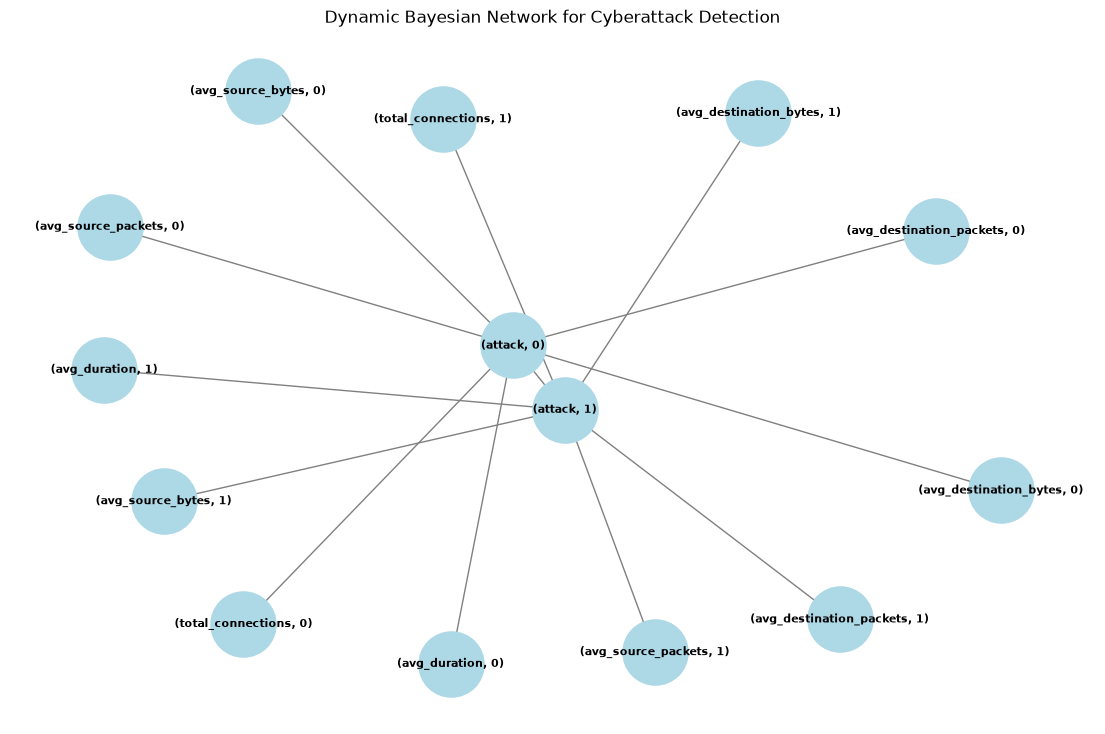

In [169]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a graph from the trained DBN
G = nx.DiGraph()

G.add_edges_from(improved_dbn_model.edges())

# Set figure size
plt.figure(figsize=(14, 9))

# Generate node positions
pos = nx.spring_layout(G, seed=42, k=1.5)

# Draw network nodes
nx.draw_networkx_nodes(
    G, pos,
    node_size=2200,
    node_color='lightblue'
)

# Draw directed edges
nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=20,
    edge_color='gray'
)

# Draw node labels
nx.draw_networkx_labels(
    G, pos,
    font_size=8,
    font_weight='bold'
)

plt.title("Dynamic Bayesian Network for Cyberattack Detection")
plt.axis('off')
plt.show()

In [170]:
print("DYNAMIC BAYESIAN NETWORK STRUCTURE")
print("----------------------------------")

for edge in improved_dbn_model.edges():
    print(f"{edge[0]}  --->  {edge[1]}")

print("\nTotal nodes:", len(improved_dbn_model.nodes()))
print("Total edges:", len(improved_dbn_model.edges()))

DYNAMIC BAYESIAN NETWORK STRUCTURE
----------------------------------
(attack, 0)  --->  (attack, 1)
(attack, 0)  --->  (total_connections, 0)
(attack, 0)  --->  (avg_source_packets, 0)
(attack, 0)  --->  (avg_destination_packets, 0)
(attack, 0)  --->  (avg_source_bytes, 0)
(attack, 0)  --->  (avg_destination_bytes, 0)
(attack, 0)  --->  (avg_duration, 0)
(attack, 1)  --->  (total_connections, 1)
(attack, 1)  --->  (avg_source_packets, 1)
(attack, 1)  --->  (avg_destination_packets, 1)
(attack, 1)  --->  (avg_source_bytes, 1)
(attack, 1)  --->  (avg_destination_bytes, 1)
(attack, 1)  --->  (avg_duration, 1)

Total nodes: 14
Total edges: 13


In [171]:
# Display attack transition probability table
print("ATTACK STATE TRANSITION CPD")
print("----------------------------")

print(
    improved_dbn_model.get_cpds(('attack', 1))
)

ATTACK STATE TRANSITION CPD
----------------------------
+------------------+---------------------+---------------------+
| (attack, 0)      | (attack, 0)(0)      | (attack, 0)(1)      |
+------------------+---------------------+---------------------+
| (attack, 1)(0.0) | 0.9805640016693495  | 0.06184784670840448 |
+------------------+---------------------+---------------------+
| (attack, 1)(1.0) | 0.01943599833065045 | 0.9381521532915955  |
+------------------+---------------------+---------------------+


In [172]:
# Display the CPD of average source packets
print("SOURCE PACKETS CONDITIONAL PROBABILITY TABLE")
print("--------------------------------------------")

print(
    improved_dbn_model.get_cpds(
        ('avg_source_packets', 0)
    )
)

SOURCE PACKETS CONDITIONAL PROBABILITY TABLE
--------------------------------------------
+----------------------------+--------------------+---------------------+
| (attack, 0)                | (attack, 0)(0)     | (attack, 0)(1)      |
+----------------------------+--------------------+---------------------+
| (avg_source_packets, 0)(0) | 0.2142133190246229 | 0.36463669132991844 |
+----------------------------+--------------------+---------------------+
| (avg_source_packets, 0)(1) | 0.516842544565671  | 0.44545627015746536 |
+----------------------------+--------------------+---------------------+
| (avg_source_packets, 0)(2) | 0.2689441364097061 | 0.1899070385126162  |
+----------------------------+--------------------+---------------------+


In [173]:
# Display all traffic feature CPDs at time t

print("TRAFFIC FEATURE CONDITIONAL PROBABILITY TABLES")
print("----------------------------------------------")

for feature in feature_columns:

    print(f"\nFeature: {feature}")

    cpd = improved_dbn_model.get_cpds((feature, 0))

    print(cpd)

TRAFFIC FEATURE CONDITIONAL PROBABILITY TABLES
----------------------------------------------

Feature: total_connections
+---------------------------+---------------------+---------------------+
| (attack, 0)               | (attack, 0)(0)      | (attack, 0)(1)      |
+---------------------------+---------------------+---------------------+
| (total_connections, 0)(0) | 0.36517021403446015 | 0.11212293682413205 |
+---------------------------+---------------------+---------------------+
| (total_connections, 0)(1) | 0.4871519704286651  | 0.4342629482071713  |
+---------------------------+---------------------+---------------------+
| (total_connections, 0)(2) | 0.14767781553687473 | 0.45361411496869664 |
+---------------------------+---------------------+---------------------+

Feature: avg_source_packets
+----------------------------+--------------------+---------------------+
| (attack, 0)                | (attack, 0)(0)     | (attack, 0)(1)      |
+----------------------------+-----

In [174]:
import pandas as pd
import matplotlib.pyplot as plt

probability_data = []

for feature in feature_columns:

    cpd = improved_dbn_model.get_cpds((feature, 0))

    for level in range(3):

        probability_data.append({
            'Feature': feature,
            'Level': ['Low', 'Medium', 'High'][level],
            'Normal': cpd.values[level, 0] * 100,
            'Attack': cpd.values[level, 1] * 100
        })

probability_df = pd.DataFrame(probability_data)

print(probability_df)

                    Feature   Level     Normal     Attack
0         total_connections     Low  36.517021  11.212294
1         total_connections  Medium  48.715197  43.426295
2         total_connections    High  14.767782  45.361411
3        avg_source_packets     Low  21.421332  36.463669
4        avg_source_packets  Medium  51.684254  44.545627
5        avg_source_packets    High  26.894414  18.990704
6   avg_destination_packets     Low  21.296131  36.843104
7   avg_destination_packets  Medium  52.149288  43.084804
8   avg_destination_packets    High  26.554582  20.072093
9          avg_source_bytes     Low  23.591486  29.482072
10         avg_source_bytes  Medium  50.783998  47.486245
11         avg_source_bytes    High  25.624516  23.031683
12    avg_destination_bytes     Low  23.281464  30.468602
13    avg_destination_bytes  Medium  50.277231  49.098843
14    avg_destination_bytes    High  26.441304  20.432555
15             avg_duration     Low  26.787098  19.351167
16            

In [175]:
# Examine how traffic features change between consecutive time points

for feature in feature_columns:

    print(f"\nFEATURE: {feature}")
    print("-" * 60)

    transition_table = pd.crosstab(
        dbn_train_improved[(feature, 0)],
        dbn_train_improved[(feature, 1)],
        normalize='index'
    )

    transition_table.index = ['Low at t', 'Medium at t', 'High at t']
    transition_table.columns = ['Low at t+1', 'Medium at t+1', 'High at t+1']

    print((transition_table * 100).round(2))


FEATURE: total_connections
------------------------------------------------------------
             Low at t+1  Medium at t+1  High at t+1
Low at t          41.63          47.56        10.81
Medium at t       30.66          51.70        17.64
High at t         14.65          38.21        47.14

FEATURE: avg_source_packets
------------------------------------------------------------
             Low at t+1  Medium at t+1  High at t+1
Low at t          30.99          48.43        20.58
Medium at t       23.74          51.53        24.73
High at t         21.59          48.49        29.92

FEATURE: avg_destination_packets
------------------------------------------------------------
             Low at t+1  Medium at t+1  High at t+1
Low at t          30.67          48.26        21.07
Medium at t       23.59          51.84        24.57
High at t         22.19          48.06        29.75

FEATURE: avg_source_bytes
------------------------------------------------------------
             L

In [176]:
from pgmpy.models import DynamicBayesianNetwork

# Create a separate experimental DBN
temporal_dbn_model = DynamicBayesianNetwork()

# Preserve the existing attack-state transition
temporal_dbn_model.add_edge(
    ('attack', 0),
    ('attack', 1)
)

# Attack state influences traffic features at time t
for feature in feature_columns:
    temporal_dbn_model.add_edge(
        ('attack', 0),
        (feature, 0)
    )

# Attack state influences traffic features at time t+1
for feature in feature_columns:
    temporal_dbn_model.add_edge(
        ('attack', 1),
        (feature, 1)
    )

# Add temporal dependencies for selected traffic features
temporal_dbn_model.add_edge(
    ('total_connections', 0),
    ('total_connections', 1)
)

temporal_dbn_model.add_edge(
    ('avg_duration', 0),
    ('avg_duration', 1)
)

# Display the new structure
print("EXPERIMENTAL DBN STRUCTURE")
print("--------------------------")

for edge in temporal_dbn_model.edges():
    print(edge)

print("\nTotal nodes:", len(temporal_dbn_model.nodes()))
print("Total edges:", len(temporal_dbn_model.edges()))

EXPERIMENTAL DBN STRUCTURE
--------------------------
(<DynamicNode(attack, 0) at 0x1f775f17710>, <DynamicNode(attack, 1) at 0x1f775f174a0>)
(<DynamicNode(attack, 0) at 0x1f775f17710>, <DynamicNode(total_connections, 0) at 0x1f7948be9c0>)
(<DynamicNode(attack, 0) at 0x1f775f17710>, <DynamicNode(avg_source_packets, 0) at 0x1f7948becf0>)
(<DynamicNode(attack, 0) at 0x1f775f17710>, <DynamicNode(avg_destination_packets, 0) at 0x1f7948bc380>)
(<DynamicNode(attack, 0) at 0x1f775f17710>, <DynamicNode(avg_source_bytes, 0) at 0x1f76f368680>)
(<DynamicNode(attack, 0) at 0x1f775f17710>, <DynamicNode(avg_destination_bytes, 0) at 0x1f76f368980>)
(<DynamicNode(attack, 0) at 0x1f775f17710>, <DynamicNode(avg_duration, 0) at 0x1f76f368dd0>)
(<DynamicNode(attack, 1) at 0x1f775f174a0>, <DynamicNode(total_connections, 1) at 0x1f7948bccb0>)
(<DynamicNode(attack, 1) at 0x1f775f174a0>, <DynamicNode(avg_source_packets, 1) at 0x1f7948bf3e0>)
(<DynamicNode(attack, 1) at 0x1f775f174a0>, <DynamicNode(avg_destinat

In [177]:
# Train the experimental DBN using Maximum Likelihood Estimation

temporal_dbn_model.fit(
    dbn_train_improved,
    estimator='MLE'
)

print("Experimental DBN training completed successfully.")

# Validate the trained model
print("Model validation:", temporal_dbn_model.check_model())

# Count learned probability tables
print("Total CPDs:", len(temporal_dbn_model.get_cpds()))

Experimental DBN training completed successfully.
Model validation: True
Total CPDs: 14


In [178]:
from pgmpy.inference import DBNInference

# Create inference engine for experimental DBN
temporal_inference = DBNInference(temporal_dbn_model)

print("Experimental DBN inference engine created successfully.")

Experimental DBN inference engine created successfully.


In [179]:
temporal_validation_probabilities = []

for index, row in dbn_validation_improved.iterrows():

    evidence = {}

    # Traffic features at time t
    for feature in feature_columns:
        evidence[(feature, 0)] = int(row[(feature, 0)])

    # Traffic features at time t+1
    for feature in feature_columns:
        evidence[(feature, 1)] = int(row[(feature, 1)])

    # Calculate attack probability at time t+1
    result = temporal_inference.forward_inference(
        variables=[('attack', 1)],
        evidence=evidence
    )

    attack_probability = result[('attack', 1)].values[1]

    temporal_validation_probabilities.append(attack_probability)

print("Validation predictions completed.")
print("Total predictions:", len(temporal_validation_probabilities))

Validation predictions completed.
Total predictions: 5510


In [180]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Actual attack labels from validation data
y_validation = dbn_validation_improved[('attack', 1)].astype(int)

# Probability thresholds to evaluate
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

temporal_results = []

for threshold in thresholds:

    # Convert probabilities into normal/attack predictions
    y_pred = (
        np.array(temporal_validation_probabilities) >= threshold
    ).astype(int)

    temporal_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_validation, y_pred, zero_division=0),
        'Recall': recall_score(y_validation, y_pred, zero_division=0),
        'F1-score': f1_score(y_validation, y_pred, zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_validation, y_pred)
    })

temporal_results_df = pd.DataFrame(temporal_results)

print("EXPERIMENTAL DBN - VALIDATION PERFORMANCE")
print("-----------------------------------------")

print(temporal_results_df.round(4).to_string(index=False))

EXPERIMENTAL DBN - VALIDATION PERFORMANCE
-----------------------------------------
 Threshold  Precision  Recall  F1-score  Balanced Accuracy
       0.1     0.2884  0.8521    0.4309             0.6280
       0.2     0.3318  0.7543    0.4608             0.6618
       0.3     0.3967  0.6483    0.4922             0.6844
       0.4     0.4520  0.5341    0.4896             0.6753
       0.5     0.5009  0.4618    0.4805             0.6657
       0.6     0.5599  0.4035    0.4690             0.6568
       0.7     0.6118  0.3057    0.4077             0.6253
       0.8     0.7259  0.1980    0.3112             0.5884
       0.9     0.8065  0.1027    0.1822             0.5479


In [181]:
# Select the best experimental DBN threshold
temporal_best_threshold = 0.3

print("Selected threshold:", temporal_best_threshold)

# Generate final validation predictions
temporal_validation_predictions = (
    np.array(temporal_validation_probabilities)
    >= temporal_best_threshold
).astype(int)

print("Validation predictions:", len(temporal_validation_predictions))

Selected threshold: 0.3
Validation predictions: 5510


In [182]:
from sklearn.metrics import roc_auc_score

temporal_validation_auc = roc_auc_score(
    y_validation,
    temporal_validation_probabilities
)

print("Experimental DBN Validation ROC-AUC:",
      round(temporal_validation_auc, 4))

Experimental DBN Validation ROC-AUC: 0.7441


In [183]:
temporal_test_probabilities = []

for index, row in dbn_test.iterrows():

    evidence = {}

    # Traffic features at time t
    for feature in feature_columns:
        evidence[(feature, 0)] = int(row[(feature, 0)])

    # Traffic features at time t+1
    for feature in feature_columns:
        evidence[(feature, 1)] = int(row[(feature, 1)])

    # Estimate attack probability
    result = temporal_inference.forward_inference(
        variables=[('attack', 1)],
        evidence=evidence
    )

    attack_probability = result[('attack', 1)].values[1]

    temporal_test_probabilities.append(attack_probability)

print("Experimental DBN test predictions completed.")
print("Total predictions:", len(temporal_test_probabilities))

Experimental DBN test predictions completed.
Total predictions: 11764


In [184]:
temporal_test_predictions = (
    np.array(temporal_test_probabilities) >= 0.3
).astype(int)

print("Threshold:", 0.3)
print("Total predictions:", len(temporal_test_predictions))
print("Predicted normal:", (temporal_test_predictions == 0).sum())
print("Predicted attacks:", (temporal_test_predictions == 1).sum())

Threshold: 0.3
Total predictions: 11764
Predicted normal: 3385
Predicted attacks: 8379


In [185]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("EXPERIMENTAL DBN - FINAL TEST RESULTS")
print("--------------------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, temporal_test_predictions), 4))

print("Attack Precision:",
      round(precision_score(y_test, temporal_test_predictions), 4))

print("Attack Recall:",
      round(recall_score(y_test, temporal_test_predictions), 4))

print("Attack F1-score:",
      round(f1_score(y_test, temporal_test_predictions), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, temporal_test_predictions), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, temporal_test_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, temporal_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    temporal_test_predictions,
    target_names=["Normal", "Attack"]
))

EXPERIMENTAL DBN - FINAL TEST RESULTS
--------------------------------------
Accuracy: 0.6888
Attack Precision: 0.9073
Attack Recall: 0.725
Attack F1-score: 0.8059
Balanced Accuracy: 0.5585
ROC-AUC: 0.5975

Confusion Matrix:
[[ 501  777]
 [2884 7602]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.15      0.39      0.21      1278
      Attack       0.91      0.72      0.81     10486

    accuracy                           0.69     11764
   macro avg       0.53      0.56      0.51     11764
weighted avg       0.82      0.69      0.74     11764



In [186]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Generate test probabilities for all four models
# --------------------------------------------------

model_probabilities = {
    "Original DBN": np.array(test_probabilities),

    "Experimental DBN": np.array(temporal_test_probabilities),

    "Logistic Regression": lr_model.predict_proba(X_test)[:, 1],

    "Random Forest": rf_model.predict_proba(X_test)[:, 1]
}

# --------------------------------------------------
# 2. Set thresholds selected using validation data
# --------------------------------------------------

model_thresholds = {
    "Original DBN": 0.3,
    "Experimental DBN": 0.3,
    "Logistic Regression": 0.5,
    "Random Forest": 0.5
}

# Actual test labels
actual_labels = np.array(y_test)

# --------------------------------------------------
# 3. Calculate performance metrics
# --------------------------------------------------

results = []
confusion_matrices = {}

for model_name, probabilities in model_probabilities.items():

    threshold = model_thresholds[model_name]

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual_labels, predictions, labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(actual_labels, predictions)

    precision = precision_score(
        actual_labels, predictions, zero_division=0
    )

    recall = recall_score(
        actual_labels, predictions, zero_division=0
    )

    f1 = f1_score(
        actual_labels, predictions, zero_division=0
    )

    balanced_accuracy = balanced_accuracy_score(
        actual_labels, predictions
    )

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    roc_auc = roc_auc_score(actual_labels, probabilities)

    results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy * 100,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1-score": f1 * 100,
        "Balanced Accuracy": balanced_accuracy * 100,
        "Specificity": specificity * 100,
        "ROC-AUC": roc_auc * 100
    })

    confusion_matrices[model_name] = np.array([
        [tn, fp],
        [fn, tp]
    ])

# --------------------------------------------------
# 4. Display final comparison table
# --------------------------------------------------

comparison_df = pd.DataFrame(results)

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Balanced Accuracy",
    "Specificity",
    "ROC-AUC"
]

comparison_df[metric_columns] = comparison_df[metric_columns].round(2)

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(comparison_df.set_index("Model"))

# --------------------------------------------------
# 5. Display confusion matrices
# --------------------------------------------------

print("\nCONFUSION MATRICES")
print("=" * 50)

for model_name, matrix in confusion_matrices.items():

    print(f"\n{model_name}")
    print("                 Predicted")
    print("                 Normal  Attack")
    print(f"Actual Normal    {matrix[0, 0]:5d}  {matrix[0, 1]:5d}")
    print(f"Actual Attack    {matrix[1, 0]:5d}  {matrix[1, 1]:5d}")

# --------------------------------------------------
# 6. Identify the best model by attack F1-score
# --------------------------------------------------

best_model = comparison_df.loc[
    comparison_df["F1-score"].idxmax()
]

print("\nBEST MODEL BASED ON ATTACK F1-SCORE")
print("=" * 50)
print("Model:", best_model["Model"])
print("F1-score:", best_model["F1-score"], "%")
print("ROC-AUC:", best_model["ROC-AUC"], "%")

FINAL MODEL PERFORMANCE COMPARISON


,Threshold,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Specificity,ROC-AUC
Model,,,,,,,,
Original DBN,0.3,69.62,90.63,73.52,81.18,55.58,37.64,60.05
Experimental DBN,0.3,68.88,90.73,72.50,80.59,55.85,39.20,59.75
Logistic Regression,0.5,74.23,90.63,79.28,84.58,56.03,32.79,61.13
Random Forest,0.5,66.92,90.68,70.09,79.07,55.51,40.92,58.36



CONFUSION MATRICES

Original DBN
                 Predicted
                 Normal  Attack
Actual Normal      481    797
Actual Attack     2777   7709

Experimental DBN
                 Predicted
                 Normal  Attack
Actual Normal      501    777
Actual Attack     2884   7602

Logistic Regression
                 Predicted
                 Normal  Attack
Actual Normal      419    859
Actual Attack     2173   8313

Random Forest
                 Predicted
                 Normal  Attack
Actual Normal      523    755
Actual Attack     3136   7350

BEST MODEL BASED ON ATTACK F1-SCORE
Model: Logistic Regression
F1-score: 84.58 %
ROC-AUC: 61.13 %



FINAL MODEL PERFORMANCE TABLE


,Model,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Specificity,ROC-AUC
0,Original DBN,69.62,90.63,73.52,81.18,55.58,37.64,60.05
1,Experimental DBN,68.88,90.73,72.50,80.59,55.85,39.20,59.75
2,Logistic Regression,74.23,90.63,79.28,84.58,56.03,32.79,61.13
3,Random Forest,66.92,90.68,70.09,79.07,55.51,40.92,58.36


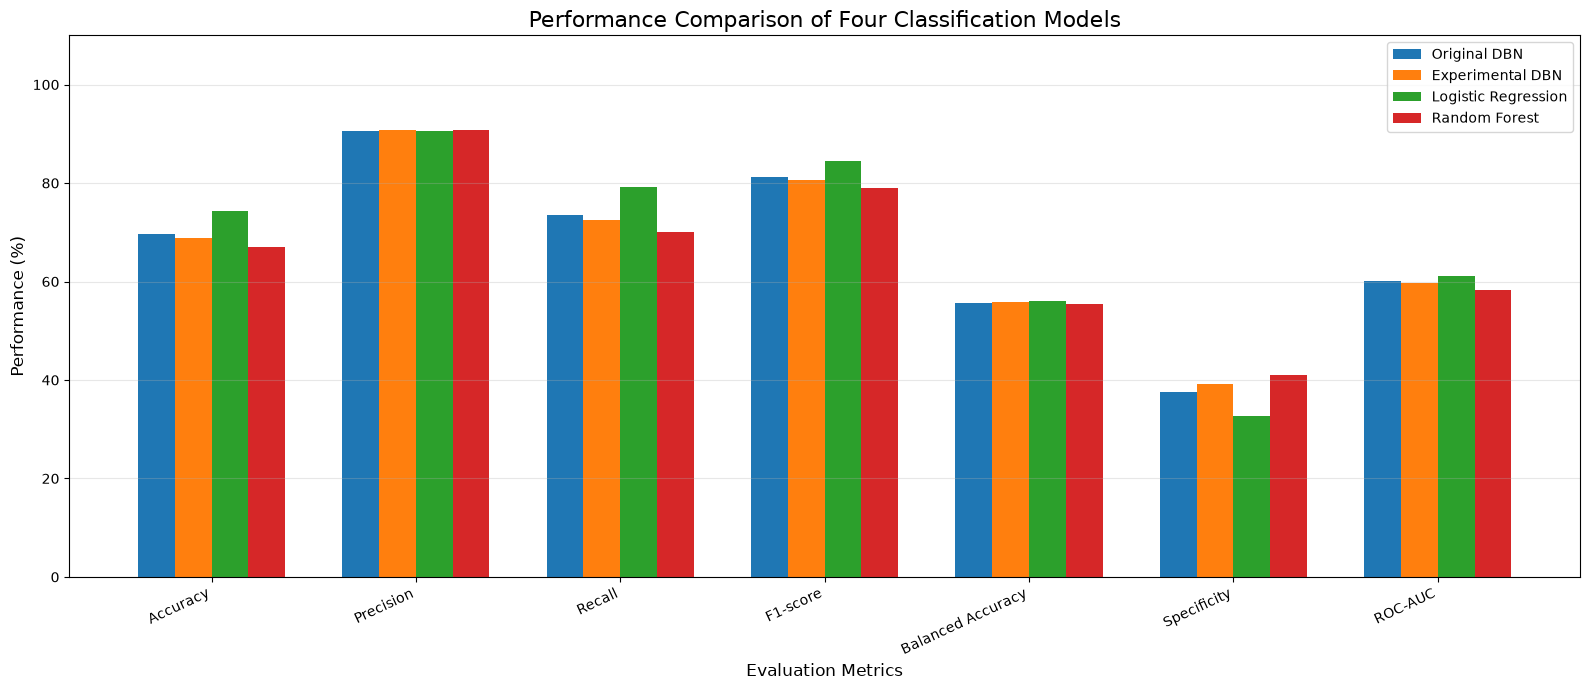

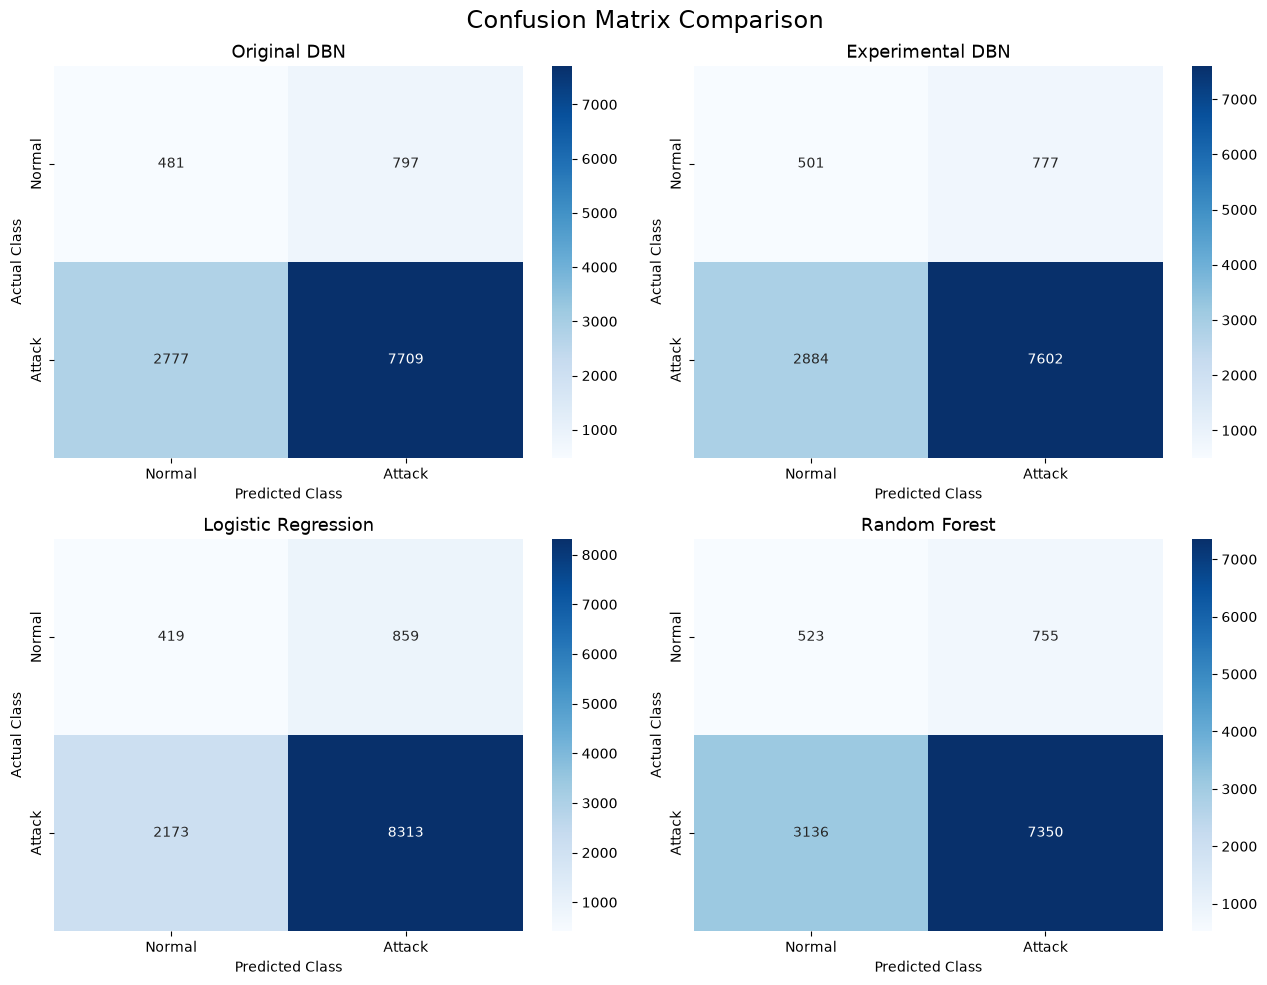

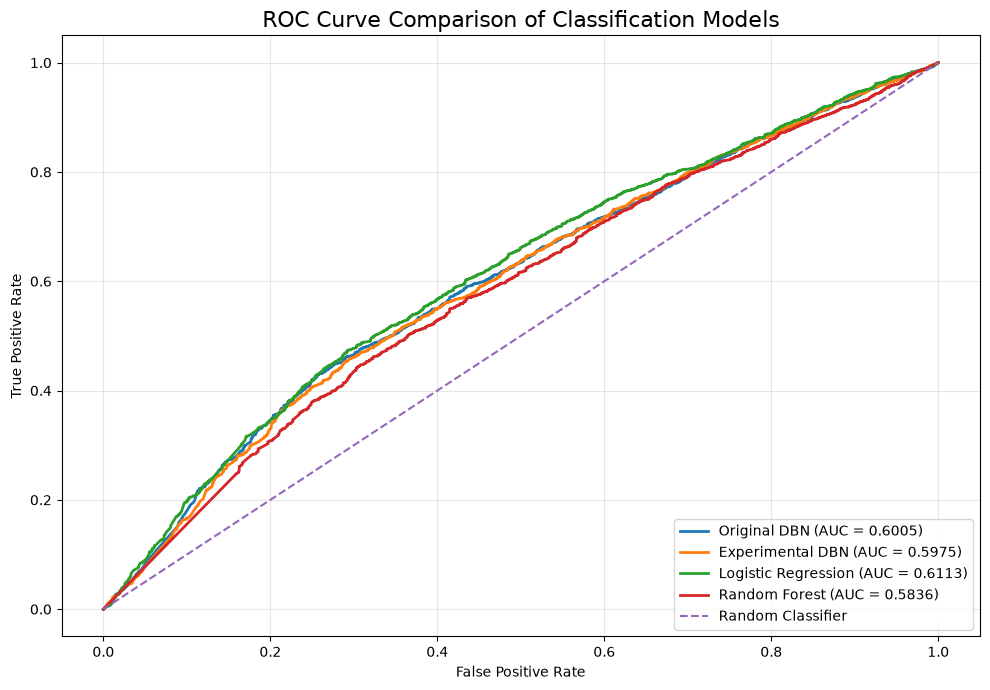

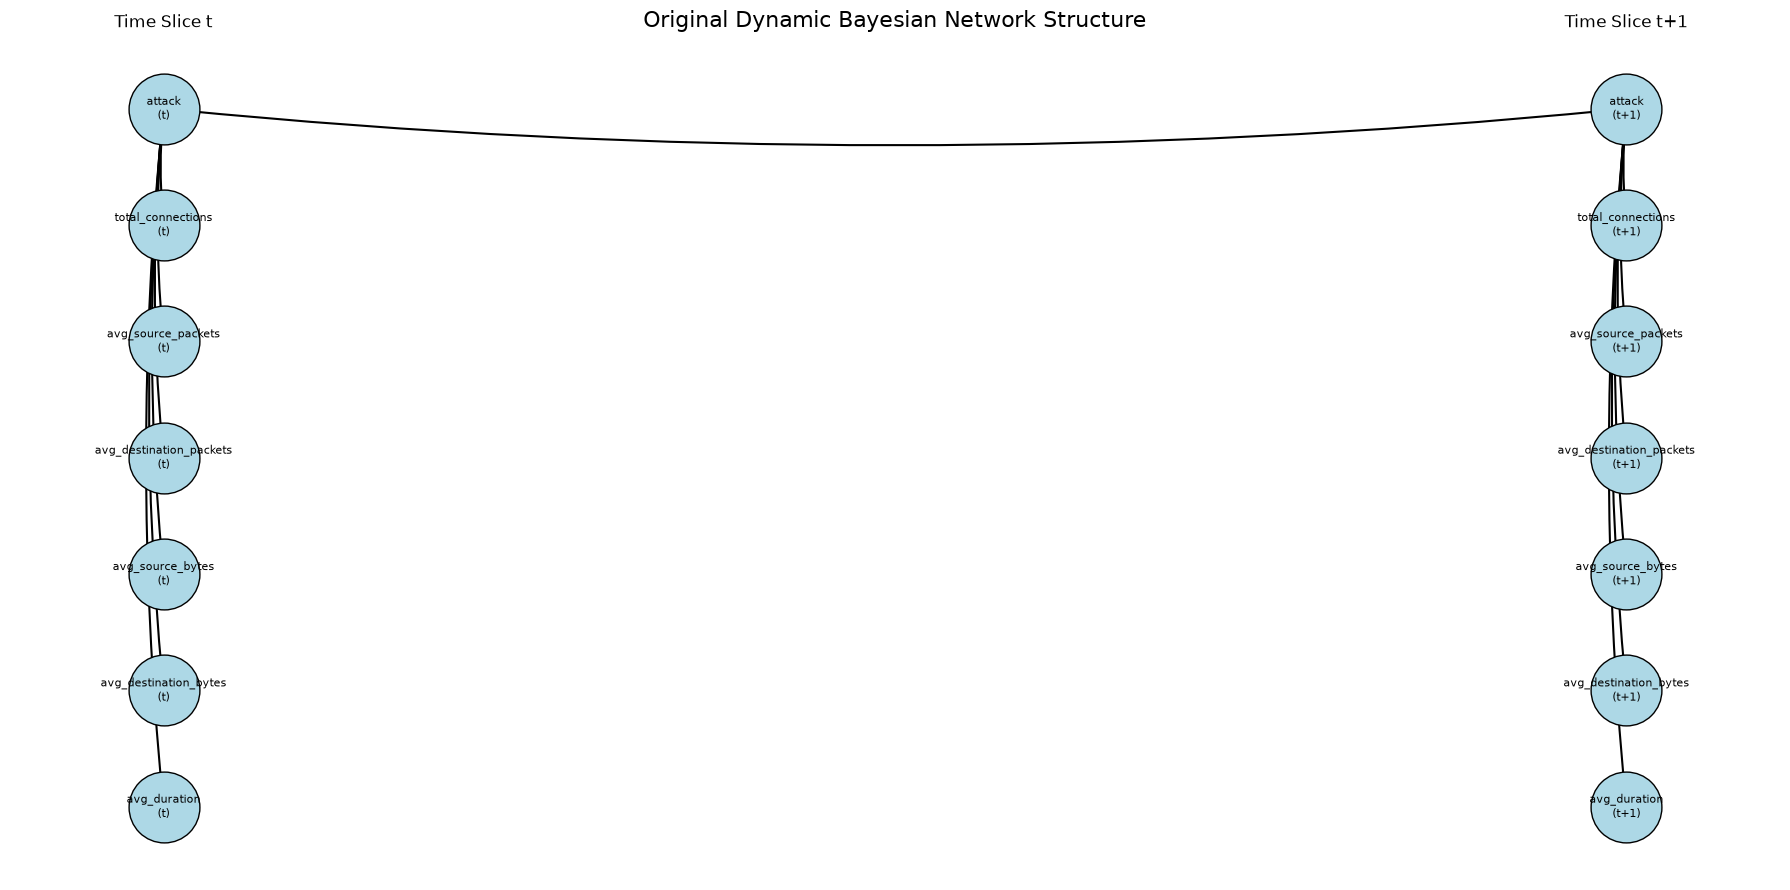

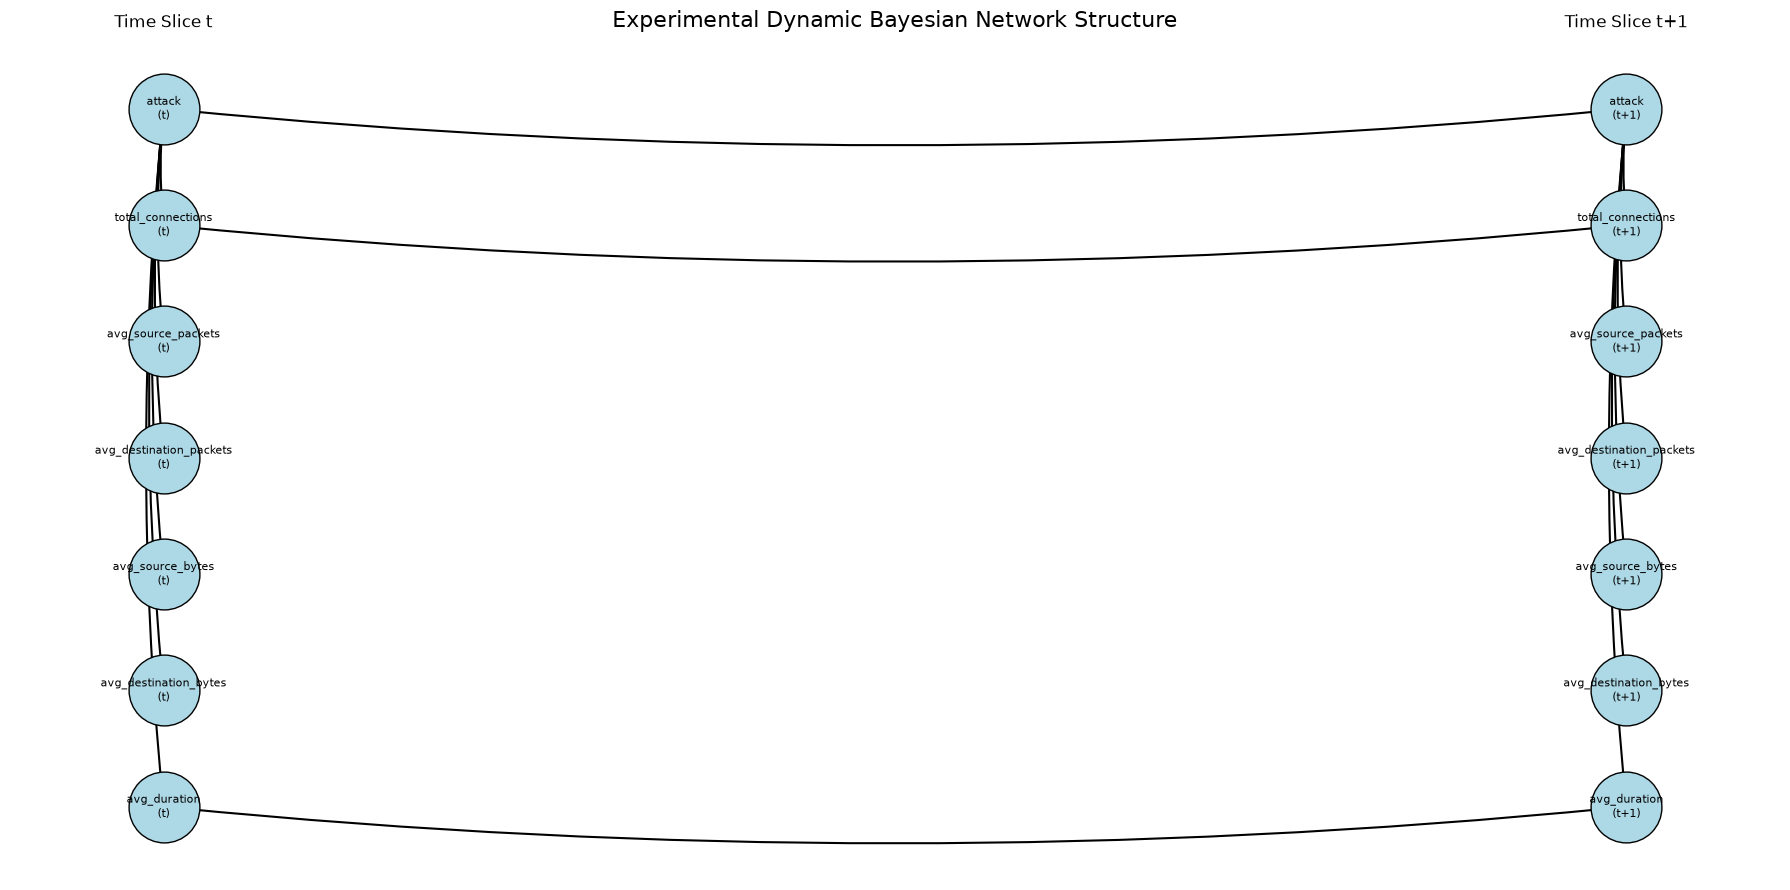


FEATURE PROBABILITY TABLE


,Feature,Level,Normal,Attack
0,total_connections,Low,36.52,11.21
1,total_connections,Medium,48.72,43.43
2,total_connections,High,14.77,45.36
3,avg_source_packets,Low,21.42,36.46
4,avg_source_packets,Medium,51.68,44.55
5,avg_source_packets,High,26.89,18.99
6,avg_destination_packets,Low,21.30,36.84
7,avg_destination_packets,Medium,52.15,43.08
8,avg_destination_packets,High,26.55,20.07
9,avg_source_bytes,Low,23.59,29.48


<Figure size 1600x800 with 0 Axes>

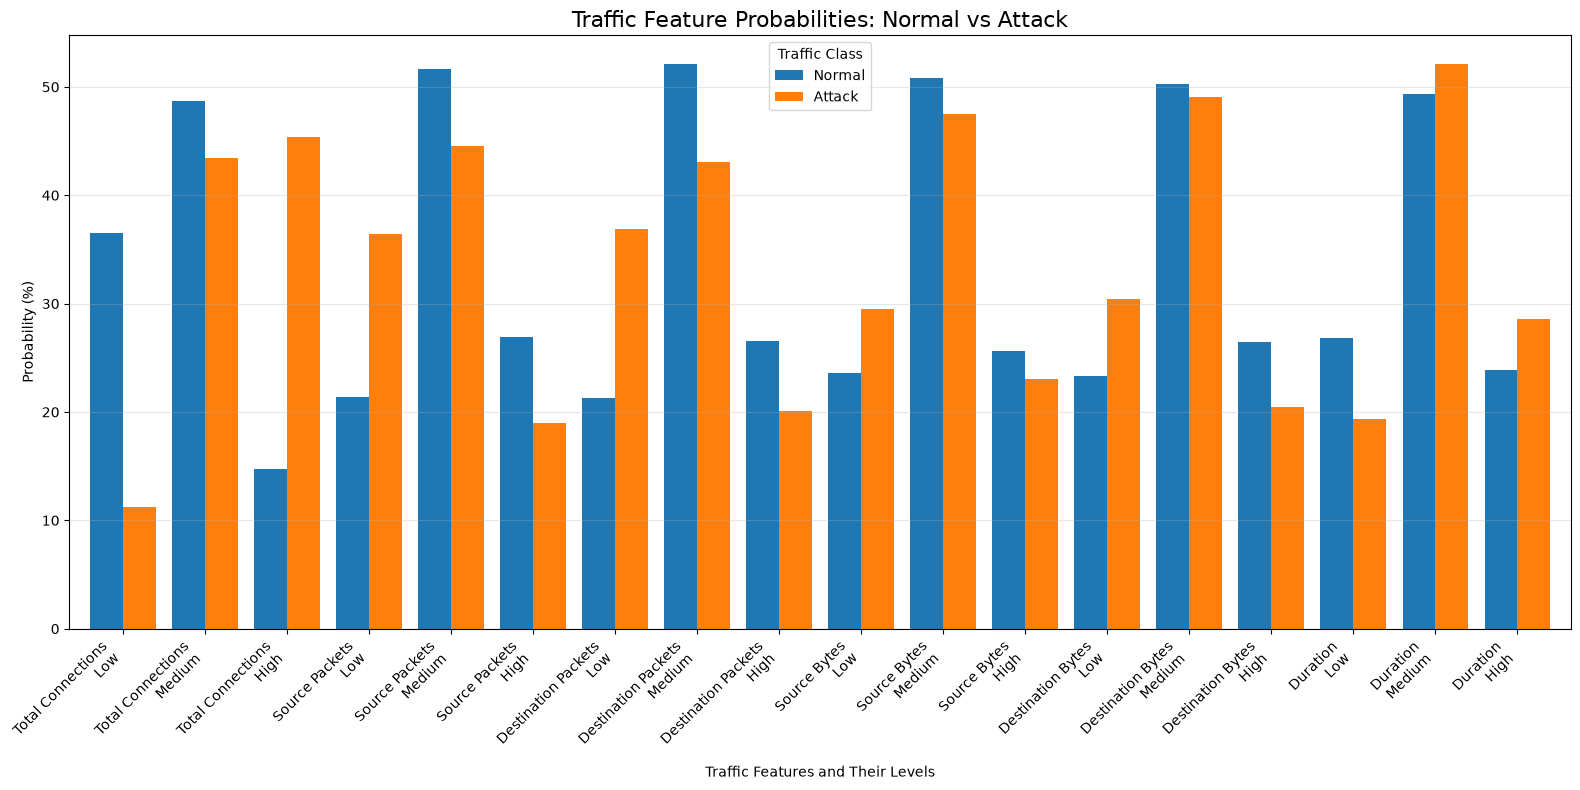


FINAL PROJECT MODEL SUMMARY
Number of Models Evaluated: 4
Test Records: 11764
Best Model: Logistic Regression
Best Attack F1-score: 84.58 %
Best ROC-AUC: 61.13 %

Proposed Project Model: Original Dynamic Bayesian Network
Experimental Model: Modified Dynamic Bayesian Network
Best Conventional Baseline: Logistic Regression

All project visualisations generated successfully.


In [187]:
# ============================================================
# CYBERATTACK DETECTION USING DYNAMIC BAYESIAN NETWORKS
# COMPLETE PROJECT VISUALISATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

# ------------------------------------------------------------
# 1. PREPARE MODEL PREDICTIONS
# ------------------------------------------------------------

actual_labels = dbn_test[('attack', 1)].astype(int).to_numpy()

model_probabilities = {
    "Original DBN": np.asarray(test_probabilities),

    "Experimental DBN": np.asarray(temporal_test_probabilities),

    "Logistic Regression": lr_model.predict_proba(X_test)[:, 1],

    "Random Forest": rf_model.predict_proba(X_test)[:, 1]
}

model_thresholds = {
    "Original DBN": 0.3,
    "Experimental DBN": 0.3,
    "Logistic Regression": 0.5,
    "Random Forest": 0.5
}

model_predictions = {}

for model_name, probabilities in model_probabilities.items():

    model_predictions[model_name] = (
        probabilities >= model_thresholds[model_name]
    ).astype(int)


# ------------------------------------------------------------
# 2. CALCULATE MODEL PERFORMANCE METRICS
# ------------------------------------------------------------

results = []

for model_name, predictions in model_predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        actual_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    results.append({

        "Model": model_name,

        "Accuracy": accuracy_score(
            actual_labels, predictions
        ) * 100,

        "Precision": precision_score(
            actual_labels, predictions, zero_division=0
        ) * 100,

        "Recall": recall_score(
            actual_labels, predictions, zero_division=0
        ) * 100,

        "F1-score": f1_score(
            actual_labels, predictions, zero_division=0
        ) * 100,

        "Balanced Accuracy": balanced_accuracy_score(
            actual_labels, predictions
        ) * 100,

        "Specificity": (
            tn / (tn + fp) * 100 if (tn + fp) > 0 else 0
        ),

        "ROC-AUC": roc_auc_score(
            actual_labels, model_probabilities[model_name]
        ) * 100
    })

comparison_df = pd.DataFrame(results)

print("\nFINAL MODEL PERFORMANCE TABLE")
print("=" * 70)

display(comparison_df.round(2))


# ------------------------------------------------------------
# 3. VISUALISATION 1: MODEL PERFORMANCE COMPARISON
# ------------------------------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Balanced Accuracy",
    "Specificity",
    "ROC-AUC"
]

x = np.arange(len(metrics))

width = 0.18

plt.figure(figsize=(16, 7))

for i, model_name in enumerate(model_probabilities.keys()):

    values = comparison_df.loc[
        comparison_df["Model"] == model_name,
        metrics
    ].values.flatten()

    plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=model_name
    )

plt.title(
    "Performance Comparison of Four Classification Models",
    fontsize=16
)

plt.xlabel("Evaluation Metrics", fontsize=12)

plt.ylabel("Performance (%)", fontsize=12)

plt.xticks(x, metrics, rotation=25, ha="right")

plt.ylim(0, 110)

plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 4. VISUALISATION 2: CONFUSION MATRIX HEATMAPS
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes = axes.flatten()

for ax, (model_name, predictions) in zip(
    axes, model_predictions.items()
):

    cm = confusion_matrix(
        actual_labels,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Attack"],
        yticklabels=["Normal", "Attack"],
        ax=ax
    )

    ax.set_title(model_name, fontsize=13)

    ax.set_xlabel("Predicted Class")

    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=17
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 5. VISUALISATION 3: ROC CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

for model_name, probabilities in model_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        actual_labels,
        probabilities
    )

    auc_value = roc_auc_score(
        actual_labels,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )

# Random classification reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "ROC Curve Comparison of Classification Models",
    fontsize=16
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 6. VISUALISATION 4: DBN NETWORK STRUCTURE
# ------------------------------------------------------------

def draw_dbn_structure(model, title):

    graph = nx.DiGraph()

    graph.add_edges_from(model.edges())

    # Define positions for both time slices
    positions = {}

    feature_positions = {
        "total_connections": 5,
        "avg_source_packets": 4,
        "avg_destination_packets": 3,
        "avg_source_bytes": 2,
        "avg_destination_bytes": 1,
        "avg_duration": 0
    }

    for node in graph.nodes():

        variable, time_slice = node

        if variable == "attack":

            positions[node] = (
                time_slice * 3,
                6
            )

        else:

            positions[node] = (
                time_slice * 3,
                feature_positions[variable]
            )

    labels = {}

    for node in graph.nodes():

        variable, time_slice = node

        time_label = "t" if time_slice == 0 else "t+1"

        labels[node] = f"{variable}\n({time_label})"

    plt.figure(figsize=(18, 9))

    nx.draw_networkx_nodes(
        graph,
        positions,
        node_size=2600,
        node_color="lightblue",
        edgecolors="black"
    )

    nx.draw_networkx_labels(
        graph,
        positions,
        labels=labels,
        font_size=8
    )

    nx.draw_networkx_edges(
        graph,
        positions,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=18,
        width=1.5,
        connectionstyle="arc3,rad=0.05"
    )

    plt.title(title, fontsize=16)

    plt.text(
        0,
        6.7,
        "Time Slice t",
        fontsize=12,
        ha="center"
    )

    plt.text(
        3,
        6.7,
        "Time Slice t+1",
        fontsize=12,
        ha="center"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()


# Original DBN
draw_dbn_structure(
    improved_dbn_model,
    "Original Dynamic Bayesian Network Structure"
)

# Experimental DBN
draw_dbn_structure(
    temporal_dbn_model,
    "Experimental Dynamic Bayesian Network Structure"
)


# ------------------------------------------------------------
# 7. VISUALISATION 5: FEATURE PROBABILITY ANALYSIS
# ------------------------------------------------------------

probability_data = []

for feature in feature_columns:

    cpd = improved_dbn_model.get_cpds(
        (feature, 0)
    )

    for level in range(3):

        probability_data.append({

            "Feature": feature,

            "Level": ["Low", "Medium", "High"][level],

            "Normal": cpd.values[level, 0] * 100,

            "Attack": cpd.values[level, 1] * 100

        })


probability_df = pd.DataFrame(probability_data)

print("\nFEATURE PROBABILITY TABLE")
print("=" * 70)

display(probability_df.round(2))


# Create readable feature labels
probability_df["Feature Level"] = (
    probability_df["Feature"]
    .str.replace("avg_", "", regex=False)
    .str.replace("_", " ", regex=False)
    .str.title()
    + "\n"
    + probability_df["Level"]
)

# Plot Normal and Attack probabilities
plot_data = probability_df.set_index(
    "Feature Level"
)[["Normal", "Attack"]]

plt.figure(figsize=(16, 8))

plot_data.plot(
    kind="bar",
    figsize=(16, 8),
    width=0.8
)

plt.title(
    "Traffic Feature Probabilities: Normal vs Attack",
    fontsize=16
)

plt.xlabel("Traffic Features and Their Levels")

plt.ylabel("Probability (%)")

plt.xticks(rotation=45, ha="right")

plt.legend(title="Traffic Class")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

best_model = comparison_df.loc[
    comparison_df["F1-score"].idxmax()
]

print("\nFINAL PROJECT MODEL SUMMARY")
print("=" * 60)

print("Number of Models Evaluated:", len(model_probabilities))

print("Test Records:", len(actual_labels))

print("Best Model:", best_model["Model"])

print("Best Attack F1-score:",
      round(best_model["F1-score"], 2), "%")

print("Best ROC-AUC:",
      round(best_model["ROC-AUC"], 2), "%")

print("\nProposed Project Model: Original Dynamic Bayesian Network")

print("Experimental Model: Modified Dynamic Bayesian Network")

print("Best Conventional Baseline: Logistic Regression")

print("\nAll project visualisations generated successfully.")